# Data Cleaning    

In [1056]:
# Import necessary libraries
import pandas as pd
import numpy as np
import hashlib

import matplotlib.pyplot as plt
import seaborn as sns

import shap

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve





In [1057]:
'''import os

path = r"D:/Ms   DSA/Module 4/Applied Machine Learning/Capstone project/Raw data"

print(os.path.exists(path))

if os.path.exists(path):
    print(os.listdir(path))'''

'import os\n\npath = r"D:/Ms   DSA/Module 4/Applied Machine Learning/Capstone project/Raw data"\n\nprint(os.path.exists(path))\n\nif os.path.exists(path):\n    print(os.listdir(path))'

In [1058]:
'''data = pd.read_csv(
    r"D:/Ms DSA/Module 4/Applied Machine Learning/Capstone project/Raw data/fao_2021_2026_applicants.csv",
    encoding="cp1252"
)'''

'data = pd.read_csv(\n    r"D:/Ms DSA/Module 4/Applied Machine Learning/Capstone project/Raw data/fao_2021_2026_applicants.csv",\n    encoding="cp1252"\n)'

In [1059]:
#data

Let encode the admission numbers and save it

In [1060]:
'''data["ID"] = data['Student Number'].apply(
    lambda x: hashlib.sha256(str(x).encode()).hexdigest()[:12]
)
data.drop(columns=['Student Number'], inplace=True)

anon_id = data.pop("ID")
data.insert(0, "ID", anon_id)'''

'data["ID"] = data[\'Student Number\'].apply(\n    lambda x: hashlib.sha256(str(x).encode()).hexdigest()[:12]\n)\ndata.drop(columns=[\'Student Number\'], inplace=True)\n\nanon_id = data.pop("ID")\ndata.insert(0, "ID", anon_id)'

In [1061]:
#data

In [1062]:
#data.info()

In [1063]:
# Let save the dataset

#data.to_csv('../data/fao_2021_2026_applicants_cleaned.csv', index=False)



# Data Cleaning 

In [1064]:
fa = pd.read_csv('../data/fao_2021_2026_applicants_cleaned.csv')
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status
0,b2b22f8cf514,Female,Bishop Gatimu Ngandu Girls' High School,B,2021,Nairobi,Kenya,NaN,Sept-24,Bachelor of Business Information Technology,,2026-01-13T11:52:55,Not Approved
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,NaN,Jan-26,Certified Public Accountant,,2026-01-13T12:35:40,Approved
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:32:19,Approved
3,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15T16:40:30,Not Approved
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,NaN,Jan-26,Diploma in Business Information Technology,,2026-02-04T10:33:58,Approved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4171,979b65c74e06,Male,Oloolaiser High School,B+,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-06-30T16:15:44,Approved
4172,eaacc0c5ad50,Female,Alliance Girls High School,A,2021,Kiambu,Kenya,NaN,Jul-21,Bachelor of Business Science in Financial Econ...,,2021-07-02T09:21:37,Approved
4173,578a9725d655,Female,Mahiga Girls Secondary School,B+,2020,Nyeri,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-07-02T17:47:34,Not Approved
4174,8cc41966d620,Male,Alliance High School,A,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-07-04T17:19:56,Approved


Let do data inspection


In [1065]:
#data inspection on Info, is null, describe, shape, columns, head, tail, columns, dtypes, unique values,

fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 4176 entries, 0 to 4175
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             4176 non-null   str  
 1   Gender         4176 non-null   str  
 2   High School    4162 non-null   str  
 3   Mean Grade     4154 non-null   str  
 4   O LEVEL YEAR   4176 non-null   int64
 5   County         4176 non-null   str  
 6   Country        4176 non-null   str  
 7   Parent Status  657 non-null    str  
 8   Intake         4176 non-null   str  
 9   Course         4176 non-null   str  
 10  Siblings       4176 non-null   str  
 11  Date Applied   4176 non-null   str  
 12  Status         4176 non-null   str  
dtypes: int64(1), str(12)
memory usage: 971.2 KB


In [1066]:
fa.isnull().sum()

ID                  0
Gender              0
High School        14
Mean Grade         22
O LEVEL YEAR        0
County              0
Country             0
Parent Status    3519
Intake              0
Course              0
Siblings            0
Date Applied        0
Status              0
dtype: int64

In [1067]:
fa.shape

(4176, 13)

In [1068]:
columns = [
    'Gender',
    'High School',
    'Mean Grade',
    'O LEVEL YEAR',
    'County',
    'Country',
    'Parent Status',
    'Intake',
    'Course',
    'Siblings',
    'Date Applied',
    'Status'
]

for col in columns:
    print(f"\n{'='*50}")
    print(f"Value Counts for: {col}")
    print(f"{'='*50}")
    print(fa[col].value_counts())


Value Counts for: Gender
Gender
Male      2271
Female    1905
Name: count, dtype: int64

Value Counts for: High School
High School
Alliance High School                89
Strathmore School                   85
Mangu High School                   74
Maseno School                       60
Nairobi School                      56
                                    ..
Kiserian Junior Seminary             1
NJABINI BOYS HIGH SCHOOL             1
Mahad Academy School                 1
St.John Paul II Mixed Sec School     1
NorthGate School                     1
Name: count, Length: 769, dtype: int64

Value Counts for: Mean Grade
Mean Grade
B+          831
B           787
B-          635
A-          628
C+          450
A           351
C           306
A LEVELS    119
C-           36
Diploma       3
E             2
D+            2
A Levels      2
D             1
SBS           1
Name: count, dtype: int64

Value Counts for: O LEVEL YEAR
O LEVEL YEAR
2023    828
2024    812
2025    774
2022    473


In [1069]:

for col in columns:
    counts = fa[col].value_counts().reset_index()
    counts.columns = [col, 'Count']
    print(f"\n{col}")
    print(counts)



Gender
   Gender  Count
0    Male   2271
1  Female   1905

High School
                          High School  Count
0                Alliance High School     89
1                   Strathmore School     85
2                   Mangu High School     74
3                       Maseno School     60
4                      Nairobi School     56
..                                ...    ...
764          Kiserian Junior Seminary      1
765          NJABINI BOYS HIGH SCHOOL      1
766              Mahad Academy School      1
767  St.John Paul II Mixed Sec School      1
768                  NorthGate School      1

[769 rows x 2 columns]

Mean Grade
   Mean Grade  Count
0          B+    831
1           B    787
2          B-    635
3          A-    628
4          C+    450
5           A    351
6           C    306
7    A LEVELS    119
8          C-     36
9     Diploma      3
10          E      2
11         D+      2
12   A Levels      2
13          D      1
14        SBS      1

O LEVEL YEAR
  

Let change the date applied column to datetime format

In [1070]:
#fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], errors='coerce')
fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], format='ISO8601')
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status
0,b2b22f8cf514,Female,Bishop Gatimu Ngandu Girls' High School,B,2021,Nairobi,Kenya,NaN,Sept-24,Bachelor of Business Information Technology,,2026-01-13 11:52:55,Not Approved
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,NaN,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved
3,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:40:30,Not Approved
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,NaN,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4171,979b65c74e06,Male,Oloolaiser High School,B+,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-06-30 16:15:44,Approved
4172,eaacc0c5ad50,Female,Alliance Girls High School,A,2021,Kiambu,Kenya,NaN,Jul-21,Bachelor of Business Science in Financial Econ...,,2021-07-02 09:21:37,Approved
4173,578a9725d655,Female,Mahiga Girls Secondary School,B+,2020,Nyeri,Kenya,NaN,Jul-21,Bachelor of Science in Electrical and Electron...,,2021-07-02 17:47:34,Not Approved
4174,8cc41966d620,Male,Alliance High School,A,2021,Nairobi,Kenya,NaN,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-07-04 17:19:56,Approved


Let check for duplicate values

In [1071]:
fa[["ID", "Course", "Status"]].duplicated().sum()

np.int64(1138)

We have 1138 duplicated values with both the ID, Course and Status. 
We will go ahead and remove duplicate where ID, Course and Status are the same while keeping one occurance.

In [1072]:
fa = fa.drop_duplicates(
    subset=["ID", "Course", "Status"], 
    keep='first'
    )

In [1073]:
fa[["ID", "Course", "Status"]].duplicated().sum()

np.int64(0)

Let check if we still have duplicated values where ID and course are the same but different Status: 

In [1074]:
fa[['ID', 'Course']].duplicated().sum()

np.int64(537)

We still have 537 duplicated values with the same id and course but different status. 

We will remove duplicates where Status = Not approved and keep the ones which is approved. 

In [1075]:
fa = fa.sort_values(by='Status', ascending=True)
fa = fa.drop_duplicates(subset=['ID', 'Course'], keep='first')

In [1076]:
fa[['ID', 'Course']].duplicated().sum()

np.int64(0)

Let treat the missingness in Parent Status

In [1077]:
fa['Parent Status'] = fa['Parent Status'].fillna('Both Parents')
fa['Parent Status'].value_counts()

Parent Status
Both Parents       2119
Father Deceased     241
Mother Deceased      95
Orphan               46
Name: count, dtype: int64

In [1078]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1 to 4173
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
dtypes: datetime64[us](1), int64(1), str(11)
memory usage: 581.1 KB


Let remove the international students from our datasets

In [1079]:
print(fa['Date Applied'].min()) 
print(fa['Date Applied'].max())

2021-01-02 13:02:32
2026-10-21 19:51:38


In [1080]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1 to 4173
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
dtypes: datetime64[us](1), int64(1), str(11)
memory usage: 581.1 KB


In [1081]:
# Let create a new column called "Application Year" that extracts the year from the "Date Applied" column.
fa['Apply_Year'] = fa['Date Applied'].dt.year
fa['Apply_Month'] = fa['Date Applied'].dt.month
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month
1,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,Both Parents,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved,2026,1
2,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved,2026,1
4,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,Both Parents,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved,2026,2
5,583dd8ac280e,Male,Lenana School,B+,2025,Kiambu,Kenya,Both Parents,Jul-26,Bachelor of Science in Informatics and Compute...,,2026-04-24 10:08:50,Approved,2026,4
7,c4f07524867a,Male,Kibuli Secondary School,A,2023,INTERNATIONAL STUDENT,Uganda,Both Parents,Jul-26,Bachelor of Business Information Technology,,2026-04-27 23:02:58,Approved,2026,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4161,f060735303f7,Female,Moi Girls High School - Nairobi,B+,2021,Nairobi,Kenya,Both Parents,Jul-21,Bachelor of Commerce,,2021-06-18 02:00:38,Not Approved,2021,6
4163,40dd450deccf,Female,Kenya High Girls,A-,2021,Migori,Kenya,Both Parents,Jul-21,Bachelor of Laws,,2021-06-19 20:15:35,Not Approved,2021,6
4166,64005080de35,Female,Aga Khan High school,B,2021,Mombasa,Kenya,Both Parents,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-06-25 17:36:55,Not Approved,2021,6
4168,430c452ce031,Male,Maseno School,B+,2019,Kiambu,Kenya,Father Deceased,Jul-21,Bachelor of Laws,,2021-06-21 21:42:05,Not Approved,2021,6


In [1082]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2501 entries, 1 to 4173
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             2501 non-null   str           
 1   Gender         2501 non-null   str           
 2   High School    2494 non-null   str           
 3   Mean Grade     2485 non-null   str           
 4   O LEVEL YEAR   2501 non-null   int64         
 5   County         2501 non-null   str           
 6   Country        2501 non-null   str           
 7   Parent Status  2501 non-null   str           
 8   Intake         2501 non-null   str           
 9   Course         2501 non-null   str           
 10  Siblings       2501 non-null   str           
 11  Date Applied   2501 non-null   datetime64[us]
 12  Status         2501 non-null   str           
 13  Apply_Year     2501 non-null   int32         
 14  Apply_Month    2501 non-null   int32         
dtypes: datetime64[us](1), int32(2), int64

In [1083]:
fa.to_csv('../data/fa_final.csv', index=False) 

# Exploratory Data Analysics

In [1084]:
fa = pd.read_csv('../data/fa_final.csv')

In [1085]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2501 entries, 0 to 2500
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             2501 non-null   str  
 1   Gender         2501 non-null   str  
 2   High School    2494 non-null   str  
 3   Mean Grade     2485 non-null   str  
 4   O LEVEL YEAR   2501 non-null   int64
 5   County         2501 non-null   str  
 6   Country        2501 non-null   str  
 7   Parent Status  2501 non-null   str  
 8   Intake         2501 non-null   str  
 9   Course         2501 non-null   str  
 10  Siblings       2501 non-null   str  
 11  Date Applied   2501 non-null   str  
 12  Status         2501 non-null   str  
 13  Apply_Year     2501 non-null   int64
 14  Apply_Month    2501 non-null   int64
dtypes: int64(3), str(12)
memory usage: 644.7 KB


In [1086]:
fa.isnull().sum()

ID                0
Gender            0
High School       7
Mean Grade       16
O LEVEL YEAR      0
County            0
Country           0
Parent Status     0
Intake            0
Course            0
Siblings          0
Date Applied      0
Status            0
Apply_Year        0
Apply_Month       0
dtype: int64

In [1087]:
fa = fa[fa['Country']=='Kenya']

In [1088]:
fa.info()

<class 'pandas.DataFrame'>
Index: 2271 entries, 0 to 2500
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ID             2271 non-null   str  
 1   Gender         2271 non-null   str  
 2   High School    2264 non-null   str  
 3   Mean Grade     2265 non-null   str  
 4   O LEVEL YEAR   2271 non-null   int64
 5   County         2271 non-null   str  
 6   Country        2271 non-null   str  
 7   Parent Status  2271 non-null   str  
 8   Intake         2271 non-null   str  
 9   Course         2271 non-null   str  
 10  Siblings       2271 non-null   str  
 11  Date Applied   2271 non-null   str  
 12  Status         2271 non-null   str  
 13  Apply_Year     2271 non-null   int64
 14  Apply_Month    2271 non-null   int64
dtypes: int64(3), str(12)
memory usage: 602.8 KB


--- Missing Value Summary ---
             Missing Count  Percentage (%)
High School              7        0.308234
Mean Grade               6        0.264201

--- Target Variable ('Status') Distribution ---
              Count  Percentage (%)
Status                             
Approved       1264         55.6583
Not Approved   1007         44.3417


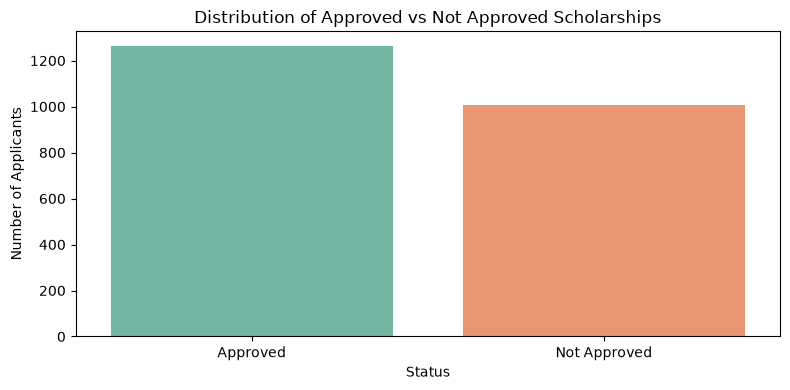

In [1089]:
print("--- Missing Value Summary ---")
missing = fa.isnull().sum()
missing_pct = (missing / len(fa)) * 100
missing_fa = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct})
print(missing_fa[missing_fa['Missing Count'] > 0])

print("\n--- Target Variable ('Status') Distribution ---")
status_counts = fa['Status'].value_counts(dropna=False)
status_pct = fa['Status'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': status_counts, 'Percentage (%)': status_pct}))

# Plot Target Distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=fa, x='Status', hue='Status', palette='Set2')
plt.title('Distribution of Approved vs Not Approved Scholarships')
plt.ylabel('Number of Applicants')
plt.tight_layout()
plt.show()

Let observe the gender distribution per scholarship distribution

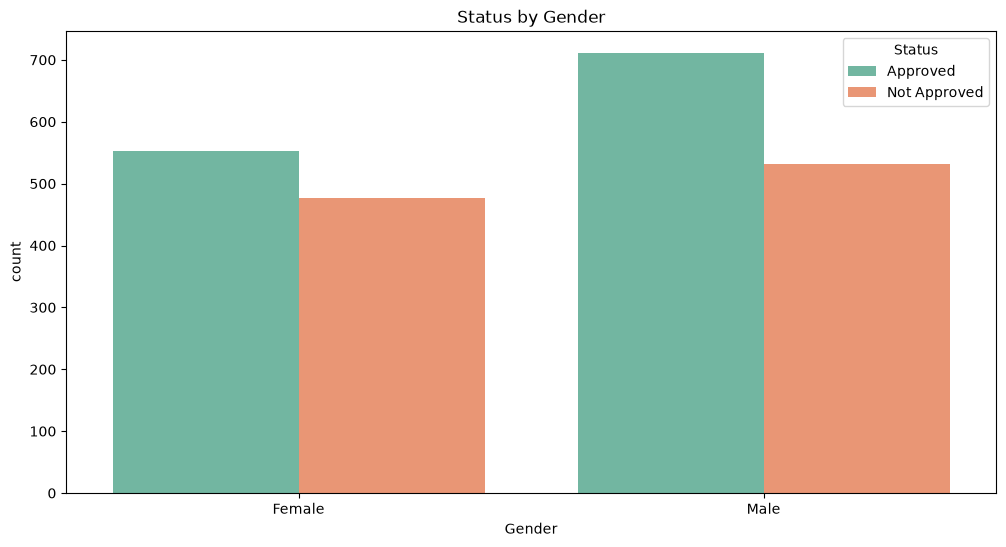

In [1090]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=fa, 
    x='Gender', 
    hue='Status', 
    palette='Set2',
)
plt.title('Status by Gender')
plt.show()

Let observe the grade status awards

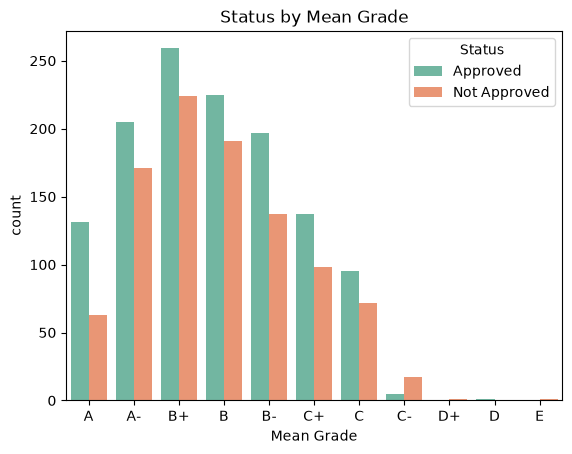

In [1091]:
grade_order = ['A', 'A-', 'B+', 'B', 'B-', 'C+', 'C', 'C-', 'D+', 'D', 'D-', 'E']
# Filter order to only available grades in dataset
existing_grades = [g for g in grade_order if g in fa['Mean Grade'].unique()]
sns.countplot(
    data=fa, 
    x='Mean Grade', 
    hue='Status', 
    order=existing_grades, 
    palette='Set2'
)
plt.title('Status by Mean Grade')
plt.show()

Let plot the parent status awards 

First we will go ahead and check how many were approved and how many were not and compute its percentage ratio.

In [1092]:
parent_counts = fa['Parent Status'].value_counts()
Approved_counts = fa[fa['Status'] == 'Approved']['Parent Status'].value_counts()
Not_Approved_counts = fa[fa['Status'] == 'Not Approved']['Parent Status'].value_counts()
approved_pct = (Approved_counts / parent_counts) * 100
not_approved_pct = (Not_Approved_counts / parent_counts) * 100 

pd.DataFrame(
    {
        'Parent Status': parent_counts, 
        'Approved': Approved_counts, 
        'Not Approved': Not_Approved_counts,
        'Approved %': approved_pct,
        'Not Approved %': not_approved_pct
    })

,Parent Status,Approved,Not Approved,Approved %,Not Approved %
Parent Status,,,,,
Both Parents,1919,1061,858,55.289213,44.710787
Father Deceased,222,130,92,58.558559,41.441441
Mother Deceased,87,49,38,56.321839,43.678161
Orphan,43,24,19,55.813953,44.186047


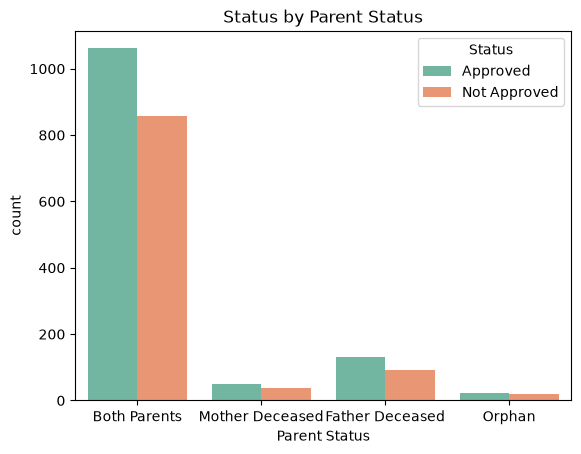

In [1093]:
sns.countplot(
    data=fa, 
    x='Parent Status', 
    hue='Status',
    palette='Set2'
)
plt.title('Status by Parent Status')
plt.show()

Let analyse the top high schools to be awarded a form of scholarship

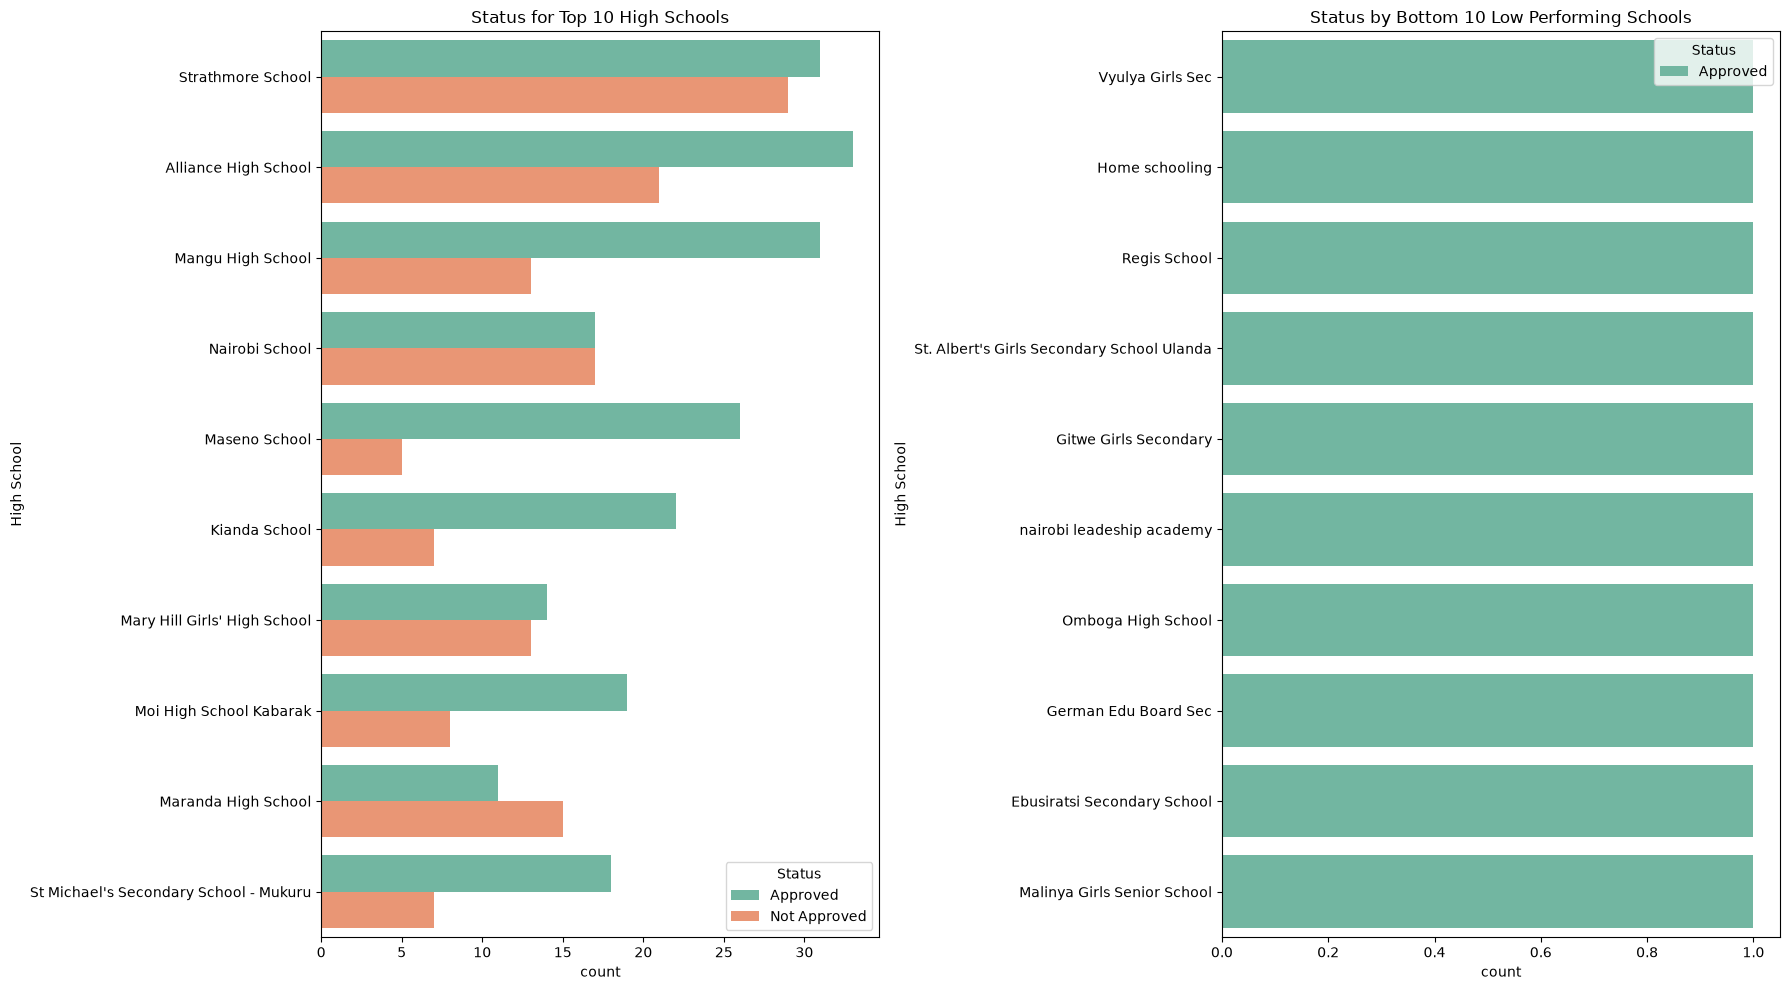

In [1094]:
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

top_schools = fa['High School'].value_counts().nlargest(10).index
sns.countplot(
    data=fa[fa['High School'].isin(top_schools)], 
    y='High School',
    hue='Status',
    order=top_schools,
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title('Status for Top 10 High Schools')

bottom_schools = fa['High School'].value_counts().nsmallest(10).index
sns.countplot(
    data=fa[fa['High School'].isin(bottom_schools)], 
    y='High School',
    hue='Status',
    order=bottom_schools,
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title('Status by Bottom 10 Low Performing Schools')

plt.tight_layout()
plt.show()


LEt observe the top 5 applied course. 

In [1095]:
fa['Course'].value_counts().nlargest()



Course
Bachelor of Science in Informatics and Computer Science    326
Bachelor of Commerce                                       301
Bachelor of Business Information Technology                252
Certified Public Accountant                                179
Diploma in Business Information Technology                 169
Name: count, dtype: int64

We will add the school/faculty type

In [1096]:
faculty = pd.read_csv('../data/su_faculty.csv')
faculty.head()

,#,Course,School
0,1,ACCA Diploma,SIMT
1,2,Association of Chartered Certified Accountants,SIMT
2,3,Bachelor of Arts Communication,SHSS
3,4,Bachelor of Arts Development Studies and Philo...,SHSS
4,5,Bachelor of Arts International Studies,SHSS


Let use the left merge to add the School/Faculty of our courses before

In [1097]:
fa = fa.merge(
    faculty[['Course', 'School']],
    on='Course',
    how='left'
)

In [1098]:
fa.head()

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month,School
0,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,Both Parents,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved,2026,1,SIMT
1,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved,2026,1,SIMT
2,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,Both Parents,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved,2026,2,SIMT
3,583dd8ac280e,Male,Lenana School,B+,2025,Kiambu,Kenya,Both Parents,Jul-26,Bachelor of Science in Informatics and Compute...,,2026-04-24 10:08:50,Approved,2026,4,SCES
4,155896ac7d72,Male,Laiser Hill Academy,B-,2025,Siaya,Kenya,Both Parents,Jul-26,Bachelor of Business Information Technology,,2026-06-19 15:15:32,Approved,2026,6,SCES


Now that we have the School Categories, let plot it and see how it behaved. 

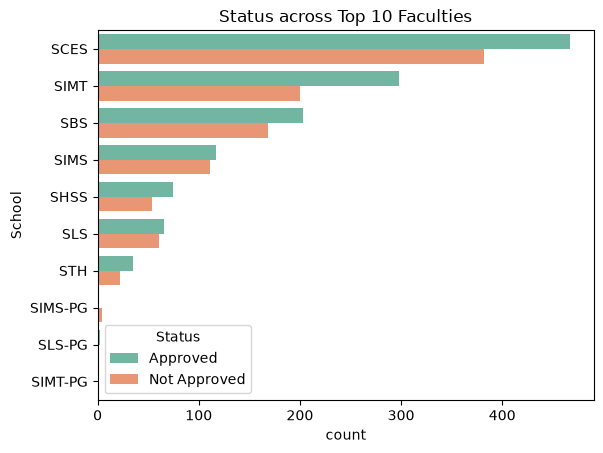

In [1099]:
top_faculties = fa['School'].value_counts().nlargest(10).index
sns.countplot(
    data=fa[fa['School'].isin(top_faculties)], 
    y='School', 
    hue='Status', 
    order=top_faculties, 
    palette='Set2'
)
plt.title('Status across Top 10 Faculties')
plt.show()

Let now observe the volume of application over time.

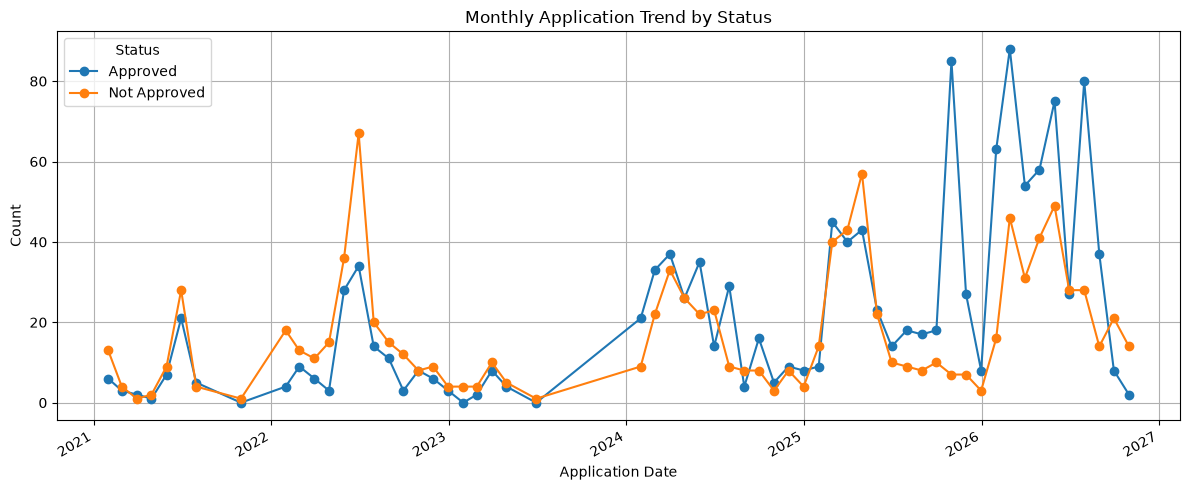

In [1100]:
fa['Date Applied'] = pd.to_datetime(fa['Date Applied'], errors='raise')

fa_data_time = (
    fa.set_index('Date Applied')
      .groupby([pd.Grouper(freq='ME'), 'Status'])
      .size()
      .unstack(fill_value=0)
)

fa_data_time.plot(kind='line', marker='o', figsize=(12, 5))
plt.title('Monthly Application Trend by Status')
plt.xlabel('Application Date')
plt.ylabel('Count')
plt.grid(True)
plt.tight_layout()
plt.show()

# Pre-treatment for Machine Learning

Let prepare the Features engineers 

#### 1. We shall convert the grade in numerical values

In [1101]:
grade_map = { # Let try giving B+ and above the same result. 
    'A': 10,
    'A-': 9,
    'B+': 8,
    'B': 7,
    'B-': 6,
    'C+': 5,
    'A LEVELS': 4,
    'DIPLOMA': 3,
    'C': 2,
    'C-': 1, #From here I decided to give all the grades below C- a value of 0 since they are not considered good grades.
    'D+': 0,
    'D': 0,
    'D-': 0,
    'E': 0
}

fa['Mean Grade'] = fa['Mean Grade'].astype(str).str.strip().str.upper()
fa['mean_grade_score'] = (
    fa['Mean Grade']
    .astype(str)
    .str.strip()
    .str.upper()
    .map(grade_map)
)

In [1102]:
fa['mean_grade_score'].value_counts().sort_index()

mean_grade_score
0.0       3
1.0      22
2.0     167
3.0       1
4.0      34
5.0     235
6.0     334
7.0     416
8.0     483
9.0     376
10.0    194
Name: count, dtype: int64

<Axes: xlabel='mean_grade_score'>

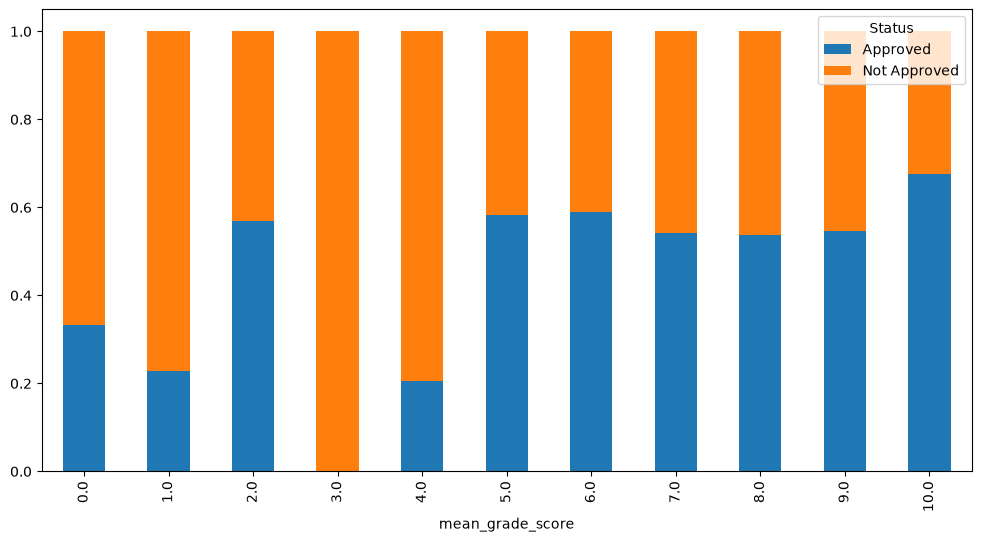

In [1103]:
Table = fa[['mean_grade_score', 'Status']]
value_counts = Table.groupby('mean_grade_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, figsize=(12, 6))

In [1104]:
fa.nunique()

ID                  2134
Gender                 2
High School          656
Mean Grade            13
O LEVEL YEAR          29
County                47
Country                1
Parent Status          4
Intake                71
Course                36
Siblings               1
Date Applied        2266
Status                 2
Apply_Year             6
Apply_Month           12
School                12
mean_grade_score      11
dtype: int64

#### 2. Let now create county vulnerability score

In [1105]:
county_vulnerability = pd.read_csv('../data/County_GVA_Contribution_Ranked_2019_2023.csv')
county_vulnerability

,Rank,County,2019 (%),2020 (%),2021 (%),2022 (%),2023 (%),5-Year Avg (%),County Rate
0,1.0,Nairobi,27.80%,27.20%,27.20%,27.70%,27.40%,27.50%,1.0
1,2.0,Kiambu,5.70%,5.60%,5.60%,5.60%,5.50%,5.60%,1.0
2,3.0,Nakuru,4.90%,4.90%,5.20%,5.20%,5.70%,5.20%,1.0
3,4.0,Mombasa,5.00%,4.80%,4.80%,4.80%,4.80%,4.80%,1.0
4,5.0,Meru,3.30%,3.30%,3.40%,3.30%,3.50%,3.40%,1.0
5,6.0,Machakos,3.20%,3.10%,3.20%,3.20%,3.20%,3.20%,2.0
6,7.0,Kisumu,2.50%,2.50%,2.50%,2.50%,2.50%,2.50%,2.0
7,8.0,Uasin Gishu,2.40%,2.30%,2.40%,2.40%,2.50%,2.40%,2.0
8,9.0,Kakamega,2.20%,2.20%,2.20%,2.20%,2.10%,2.20%,2.0
9,10.0,Kilifi,2.10%,2.00%,2.10%,2.10%,2.10%,2.10%,6.0


In [1106]:
fa['County'] = fa['County'].str.strip()
county_vulnerability['County'] = county_vulnerability['County'].str.strip()

In [1107]:
fa = fa.merge(
    county_vulnerability[['County', 'County Rate']],
    on='County',
    how='left'
)

In [1108]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2271 entries, 0 to 2270
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ID                2271 non-null   str           
 1   Gender            2271 non-null   str           
 2   High School       2264 non-null   str           
 3   Mean Grade        2265 non-null   str           
 4   O LEVEL YEAR      2271 non-null   int64         
 5   County            2271 non-null   str           
 6   Country           2271 non-null   str           
 7   Parent Status     2271 non-null   str           
 8   Intake            2271 non-null   str           
 9   Course            2271 non-null   str           
 10  Siblings          2271 non-null   str           
 11  Date Applied      2271 non-null   datetime64[us]
 12  Status            2271 non-null   str           
 13  Apply_Year        2271 non-null   int64         
 14  Apply_Month       2271 non-null   i

In [1109]:
county_null = fa.loc[fa['County Rate'].isna(), 'County']
county_null.value_counts()

County
INTERNATIONAL STUDENT    2
Name: count, dtype: int64

We have identified international students who applied for scholarship we are going to drop them since our analysis will be Kenya Focus. 


In [1110]:
fa = fa[fa['County'] != 'INTERNATIONAL STUDENT'].copy()
fa['County'].value_counts().sort_index()

County
Baringo             10
Bomet                5
Bungoma             51
Busia               36
Elgeyo Marakwet      2
Embu                13
Garissa              2
Homa Bay            49
Isiolo               3
Kajiado             93
Kakamega            82
Kericho             22
Kiambu             197
Kilifi              12
Kirinyaga           16
Kisii               60
Kisumu              90
Kitui               40
Kwale                6
Laikipia            16
Lamu                 1
Machakos            83
Makueni             44
Mandera              4
Marsabit             6
Meru                24
Migori              30
Mombasa             47
Murang'a            41
Nairobi            781
Nakuru              59
Nandi               13
Narok                9
Nyamira             18
Nyandarua           20
Nyeri               43
Samburu             23
Siaya               93
Taita Taveta        17
Tana River           7
Tharaka Nithi        8
Trans Nzoia         30
Turkana              3
Uasi

<Axes: xlabel='County Rate'>

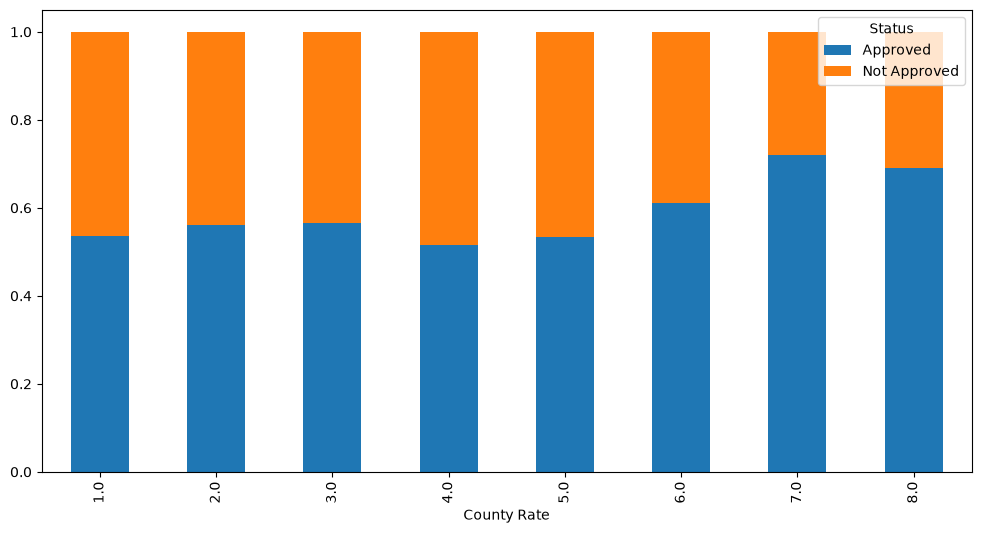

In [1111]:
# Show the award 
Table = fa[['County Rate', 'Status']]
value_counts = Table.groupby('County Rate')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, 
                  figsize=(12, 6))

### We will comment this section and use the next section


#### Collins Dataset 

To rate High School Distributions

In [1112]:
'''highschool = pd.read_csv('../data/2015-School-Masterlist.csv')
highschool'''

"highschool = pd.read_csv('../data/2015-School-Masterlist.csv')\nhighschool"

In [1113]:
'''highschool.info()'''

'highschool.info()'

In [1114]:
'''fa
highschool'''

'fa\nhighschool'

In [1115]:
'''import re
from rapidfuzz import fuzz, process'''

'import re\nfrom rapidfuzz import fuzz, process'

##### Standardization and Exact Matching 


In [1116]:
'''def clean_school_name(name):
  if pd.isna(name):
    return ""
  # Convert to uppercase
  name = str(name).upper()
  # Remove punctuation and special characters (keep alphanumeric and spaces)
  name = re.sub(r"[^\w\s]", "", name)
  # Normalize multiple spaces to a single space
  name = re.sub(r"\s+", " ", name).strip()
  return name


# 1. Create standardized columns for both datasets
fa["clean_school"] = fa["High School"].apply(clean_school_name)
highschool["clean_school"] = highschool["SCHOOL_NAME"].apply(clean_school_name)

# 2. Build a lookup dictionary from reference dataset for exact matches
cluster_lookup = highschool.set_index("clean_school")[
    "NAME_TYPE_SCHOOL_CLUSTER"
].to_dict()

# Map exact matches onto fao_data
fa["NAME_TYPE_SCHOOL_CLUSTER"] = fa["clean_school"].map(
    cluster_lookup
)'''

<>:7: SyntaxWarning: invalid escape sequence '\w'
<>:7: SyntaxWarning: invalid escape sequence '\w'
C:\Users\user\AppData\Local\Temp\ipykernel_31868\4020856360.py:7: SyntaxWarning: invalid escape sequence '\w'
  name = re.sub(r"[^\w\s]", "", name)


'def clean_school_name(name):\n  if pd.isna(name):\n    return ""\n  # Convert to uppercase\n  name = str(name).upper()\n  # Remove punctuation and special characters (keep alphanumeric and spaces)\n  name = re.sub(r"[^\\w\\s]", "", name)\n  # Normalize multiple spaces to a single space\n  name = re.sub(r"\\s+", " ", name).strip()\n  return name\n\n\n# 1. Create standardized columns for both datasets\nfa["clean_school"] = fa["High School"].apply(clean_school_name)\nhighschool["clean_school"] = highschool["SCHOOL_NAME"].apply(clean_school_name)\n\n# 2. Build a lookup dictionary from reference dataset for exact matches\ncluster_lookup = highschool.set_index("clean_school")[\n    "NAME_TYPE_SCHOOL_CLUSTER"\n].to_dict()\n\n# Map exact matches onto fao_data\nfa["NAME_TYPE_SCHOOL_CLUSTER"] = fa["clean_school"].map(\n    cluster_lookup\n)'

##### Fuzzy Matching for Remaining Records with Safety Thresholds

In [1117]:
'''fa.columns'''

'fa.columns'

In [1118]:
'''import numpy as np'''

'import numpy as np'

In [1119]:
'''master_list = fa['High School']

duplicate_count = master_list.duplicated().sum()
print("Number of duplicates:", duplicate_count)

master_list = master_list.drop_duplicates()

master_list'''

'master_list = fa[\'High School\']\n\nduplicate_count = master_list.duplicated().sum()\nprint("Number of duplicates:", duplicate_count)\n\nmaster_list = master_list.drop_duplicates()\n\nmaster_list'

In [1120]:
#master_list = master_list.to_frame(name="High School")

In [1121]:
#master_list = master_list.dropna(subset=['High School']).copy()


In [1122]:
#highschool.columns

In [1123]:
#df = highschool[['SCHOOL_NAME','NAME_TYPE_SCHOOL_CLUSTER']]
#df = df.drop_duplicates()
#df

Let try and match the messy master_list with df

In [1124]:
'''from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity'''

'from sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.metrics.pairwise import cosine_similarity'

In [1125]:
'''# Let prepare and clean the text upper case for both df and master list

df_clean = df.dropna(subset=['SCHOOL_NAME']).copy()
df_clean['CLEAN_NAME'] = df_clean['SCHOOL_NAME'].astype(str).str.upper().str.strip()

master_clean = master_list.dropna(subset=['High School']).copy()
master_clean['CLEAN_NAME'] = master_clean['High School'].astype(str).str.upper().str.strip()'''

"# Let prepare and clean the text upper case for both df and master list\n\ndf_clean = df.dropna(subset=['SCHOOL_NAME']).copy()\ndf_clean['CLEAN_NAME'] = df_clean['SCHOOL_NAME'].astype(str).str.upper().str.strip()\n\nmaster_clean = master_list.dropna(subset=['High School']).copy()\nmaster_clean['CLEAN_NAME'] = master_clean['High School'].astype(str).str.upper().str.strip()"

In [1126]:
'''# 2. Fit TF-IDF Vectorizer using character n-grams to capture substrings and typos

vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4))
df_tfidf = vectorizer.fit_transform(df_clean['CLEAN_NAME'])
master_tfidf = vectorizer.transform(master_clean['CLEAN_NAME'])'''

"# 2. Fit TF-IDF Vectorizer using character n-grams to capture substrings and typos\n\nvectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4))\ndf_tfidf = vectorizer.fit_transform(df_clean['CLEAN_NAME'])\nmaster_tfidf = vectorizer.transform(master_clean['CLEAN_NAME'])"

In [1127]:
'''# Let now compute the cosine similarity 

similarity_matrix = cosine_similarity(master_tfidf, df_tfidf)
similarity_matrix'''

'# Let now compute the cosine similarity \n\nsimilarity_matrix = cosine_similarity(master_tfidf, df_tfidf)\nsimilarity_matrix'

In [1128]:
'''# Let extract best matches and scores

best_match_indices = similarity_matrix.argmax(axis=1)
similarity_scores = similarity_matrix.max(axis=1)'''

'# Let extract best matches and scores\n\nbest_match_indices = similarity_matrix.argmax(axis=1)\nsimilarity_scores = similarity_matrix.max(axis=1)'

In [1129]:
'''# 5. Map attributes back to your master table
master_list['Matched_Official_Name'] = df_clean['SCHOOL_NAME'].iloc[best_match_indices].values
master_list['School_Category'] = df_clean['NAME_TYPE_SCHOOL_CLUSTER'].iloc[best_match_indices].values
master_list['Similarity_Score'] = similarity_scores'''

"# 5. Map attributes back to your master table\nmaster_list['Matched_Official_Name'] = df_clean['SCHOOL_NAME'].iloc[best_match_indices].values\nmaster_list['School_Category'] = df_clean['NAME_TYPE_SCHOOL_CLUSTER'].iloc[best_match_indices].values\nmaster_list['Similarity_Score'] = similarity_scores"

In [1130]:
#master_list

In [1131]:
'''# LEt separate high confidence to low confidence

# Separate high-confidence matches vs low-confidence/unmatched rows
high_confidence_df = master_list[master_list['Similarity_Score'] >= 0.70].copy()
low_confidence_df = master_list[master_list['Similarity_Score'] < 0.70].copy()

print(f"Locked & Verified (>= 70%): {len(high_confidence_df)} rows")
print(f"Requires Review (< 70%): {len(low_confidence_df)} rows")'''

'# LEt separate high confidence to low confidence\n\n# Separate high-confidence matches vs low-confidence/unmatched rows\nhigh_confidence_df = master_list[master_list[\'Similarity_Score\'] >= 0.70].copy()\nlow_confidence_df = master_list[master_list[\'Similarity_Score\'] < 0.70].copy()\n\nprint(f"Locked & Verified (>= 70%): {len(high_confidence_df)} rows")\nprint(f"Requires Review (< 70%): {len(low_confidence_df)} rows")'

In [1132]:
'''low_confidence_df'''

'low_confidence_df'

In [1133]:
'''# Let now export low-confidence rows to csv for a rapid excel editing

# 1. Isolate the low-confidence records
low_confidence_df = master_list[master_list['Similarity_Score'] < 0.70].copy()

# 2. Export to CSV for quick editing
low_confidence_df.to_csv('../data/schools_to_review.csv', index=True)
print("Exported low-confidence rows to 'schools_to_review.csv'. Open in Excel to fix quickly!")'''

'# Let now export low-confidence rows to csv for a rapid excel editing\n\n# 1. Isolate the low-confidence records\nlow_confidence_df = master_list[master_list[\'Similarity_Score\'] < 0.70].copy()\n\n# 2. Export to CSV for quick editing\nlow_confidence_df.to_csv(\'../data/schools_to_review.csv\', index=True)\nprint("Exported low-confidence rows to \'schools_to_review.csv\'. Open in Excel to fix quickly!")'

In [1134]:
'''# Let's extract tokens (words longer than 3 characters) to search the official df
def find_best_token_match(school_name, df_official):
    if pd.isna(school_name):
        return None, None, 0.0
    
    # Clean and split words
    words = [w.upper() for w in str(school_name).split() if len(w) > 3]
    if not words:
        return None, None, 0.0
    
    # Try searching with the most unique-looking word (skip generic words like 'HIGH', 'SCHOOL', 'SECONDARY')
    stop_words = {'HIGH', 'SCHOOL', 'SECONDARY', 'MIXED', 'BOYS', 'GIRLS', 'DAY', 'THE'}
    meaningful_words = [w for w in words if w not in stop_words]
    
    search_word = meaningful_words[-1] if meaningful_words else words[0]
    
    matches = df_official[df_official['SCHOOL_NAME'].str.contains(search_word, case=False, na=False)]
    if not matches.empty:
        # Return the first match found by keyword
        matched_row = matches.iloc[0]
        return matched_row['SCHOOL_NAME'], matched_row['NAME_TYPE_SCHOOL_CLUSTER'], 0.75
        
    return None, None, 0.0

# Apply to your remaining rows
for idx, row in low_confidence_df[low_confidence_df['Similarity_Score'] < 0.70].iterrows():
    match_name, match_cat, score = find_best_token_match(row['High School'], df)
    if match_name:
        low_confidence_df.loc[idx, 'Matched_Official_Name'] = match_name
        low_confidence_df.loc[idx, 'School_Category'] = match_cat
        low_confidence_df.loc[idx, 'Similarity_Score'] = score'''

"# Let's extract tokens (words longer than 3 characters) to search the official df\ndef find_best_token_match(school_name, df_official):\n    if pd.isna(school_name):\n        return None, None, 0.0\n\n    # Clean and split words\n    words = [w.upper() for w in str(school_name).split() if len(w) > 3]\n    if not words:\n        return None, None, 0.0\n\n    # Try searching with the most unique-looking word (skip generic words like 'HIGH', 'SCHOOL', 'SECONDARY')\n    stop_words = {'HIGH', 'SCHOOL', 'SECONDARY', 'MIXED', 'BOYS', 'GIRLS', 'DAY', 'THE'}\n    meaningful_words = [w for w in words if w not in stop_words]\n\n    search_word = meaningful_words[-1] if meaningful_words else words[0]\n\n    matches = df_official[df_official['SCHOOL_NAME'].str.contains(search_word, case=False, na=False)]\n    if not matches.empty:\n        # Return the first match found by keyword\n        matched_row = matches.iloc[0]\n        return matched_row['SCHOOL_NAME'], matched_row['NAME_TYPE_SCHOOL_CLUST

In [1135]:
'''import re
import pandas as pd
from rapidfuzz import process, fuzz

def clean_school_name(name):
    """
    Cleans school names by converting to uppercase, stripping trailing 
    metadata/IDs (e.g., '-6818 NAIROBI'), and removing common boilerplate 
    words that cause false positive matches.
    """
    if pd.isna(name):
        return ""
    text = str(name).upper()
    
    # 1. Remove trailing ID codes and locations like "-6818 NAIROBI" or "- 24 NDHIWA"
    text = re.sub(r'-\s*\d+.*$', '', text)
    
    # 2. Remove common boilerplate words that dominate character-based matching
    noise_words = ['SECONDARY', 'SCHOOL', 'HIGH', 'BOYS', 'GIRLS', 'MIXED', 'DAY', 'BOARDING']
    words = [w for w in text.split() if w not in noise_words]
    
    return " ".join(words).strip()


# ==========================================
# STEP 1: PREPARE AND CLEAN BOTH DATASETS
# ==========================================
df_clean = df.dropna(subset=['SCHOOL_NAME']).copy()
df_clean['SEARCH_NAME'] = df_clean['SCHOOL_NAME'].apply(clean_school_name)

master_clean = master_list.dropna(subset=['High School']).copy()
master_clean['SEARCH_NAME'] = master_clean['High School'].apply(clean_school_name)


# ==========================================
# STEP 2: FUZZY MATCH USING RAPIDFUZZ (TOKEN SET)
# ==========================================
matched_official_names = []
matched_categories = []
similarity_scores = []

# Extract reference arrays for fast index lookup
official_names = df_clean['SCHOOL_NAME'].values
official_categories = df_clean['NAME_TYPE_SCHOOL_CLUSTER'].values
search_choices = df_clean['SEARCH_NAME'].tolist()

for query in master_clean['SEARCH_NAME']:
    if not query:
        matched_official_names.append(None)
        matched_categories.append(None)
        similarity_scores.append(0.0)
        continue
        
    # Find the best match using token_set_ratio (ignores word order & extra noise words)
    result = process.extractOne(
        query, 
        search_choices, 
        scorer=fuzz.token_set_ratio
    )
    
    if result:
        matched_text, score, idx = result
        # Convert RapidFuzz score from 0-100 scale to 0.0-1.0 scale
        norm_score = score / 100.0
        
        matched_official_names.append(official_names[idx])
        matched_categories.append(official_categories[idx])
        similarity_scores.append(norm_score)
    else:
        matched_official_names.append(None)
        matched_categories.append(None)
        similarity_scores.append(0.0)


# ==========================================
# STEP 3: MAP ATTRIBUTES BACK TO MASTER LIST SAFELY
# ==========================================
master_list['Matched_Official_Name'] = None
master_list['School_Category'] = None
master_list['Similarity_Score'] = 0.0

# Assign results using original row indexes to prevent length mismatch errors
master_list.loc[master_clean.index, 'Matched_Official_Name'] = matched_official_names
master_list.loc[master_clean.index, 'School_Category'] = matched_categories
master_list.loc[master_clean.index, 'Similarity_Score'] = similarity_scores


# ==========================================
# STEP 4: SEPARATE HIGH VS LOW CONFIDENCE
# ==========================================
high_confidence_df = master_list[master_list['Similarity_Score'] >= 0.75].copy()
low_confidence_df = master_list[master_list['Similarity_Score'] < 0.75].copy()

print(f"Locked & Verified (>= 75%): {len(high_confidence_df)} rows")
print(f"Requires Review (< 75%): {len(low_confidence_df)} rows")

# Optional: Export low confidence rows for human inspection
#low_confidence_df[['High School', 'Matched_Official_Name', 'Similarity_Score']].to_csv('../data/schools_to_review.csv', index=False)'''

<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\s'
C:\Users\user\AppData\Local\Temp\ipykernel_31868\2639131120.py:16: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub(r'-\s*\d+.*$', '', text)


'import re\nimport pandas as pd\nfrom rapidfuzz import process, fuzz\n\ndef clean_school_name(name):\n    """\n    Cleans school names by converting to uppercase, stripping trailing \n    metadata/IDs (e.g., \'-6818 NAIROBI\'), and removing common boilerplate \n    words that cause false positive matches.\n    """\n    if pd.isna(name):\n        return ""\n    text = str(name).upper()\n\n    # 1. Remove trailing ID codes and locations like "-6818 NAIROBI" or "- 24 NDHIWA"\n    text = re.sub(r\'-\\s*\\d+.*$\', \'\', text)\n\n    # 2. Remove common boilerplate words that dominate character-based matching\n    noise_words = [\'SECONDARY\', \'SCHOOL\', \'HIGH\', \'BOYS\', \'GIRLS\', \'MIXED\', \'DAY\', \'BOARDING\']\n    words = [w for w in text.split() if w not in noise_words]\n\n    return " ".join(words).strip()\n\n\n# ==========================================\n# STEP 1: PREPARE AND CLEAN BOTH DATASETS\n# ==========================================\ndf_clean = df.dropna(subset=[\'SCHOOL

In [1136]:
#low_confidence_df

In [1137]:
#low_confidence_df.to_csv('../data/low_confidence.csv', index=False)


In [1138]:
#df['NAME_TYPE_SCHOOL_CLUSTER'].value_counts()

In [1139]:
#master_list['School_Category'].value_counts()

### Let continue from here

We will use the the school tier from the LLM architecture. 


We will start by inputing the High school category column before inputing anything else.

In [1140]:
high_school = pd.read_csv("../data/school_classifications.csv")
high_school.head()

,High School,High School Category,confidence,reason
0,A.I.C Ebenezer Academy,PRIVATE,0.8,The name 'Academy' suggests it is a private in...
1,Abba Salama Academy,PRIVATE,0.8,The name 'Academy' is often associated with pr...
2,Acacia Crest Senior School,PRIVATE,0.8,The name 'Acacia Crest Senior School' suggests...
3,ACADEMIA SCHOOL OF KIBERA,PRIVATE,0.8,The name 'ACADEMIA SCHOOL' suggests a private ...
4,Aga Khan Academy,PRIVATE,1.0,The Aga Khan Academy is a well-known private s...


In [1141]:
fa['High School'] = fa['High School'].str.strip()
high_school['High School'] = high_school['High School'].str.strip()

In [1142]:
fa = fa.merge(
    high_school[['High School', 'High School Category']],
    on='High School',
    how='left'
)

In [1143]:
fa['High School Category'].value_counts()

High School Category
NATIONAL         924
SUB_COUNTY       609
PRIVATE          598
UNKNOWN           78
COUNTY            14
INTERNATIONAL      4
Name: count, dtype: int64

In [1144]:
# Let create high school category score based on the high school category.
# I will assign 1 to international, 2 to national, 3 to private, 4 to unknown, 5 to county, and 6 to sub-county. 
# The Higher the score, the better the school category.

school_category_map = {
    'INTERNATIONAL': 0,
    'NATIONAL': 2,
    'PRIVATE': 3,
    'UNKNOWN': 4,
    'COUNTY': 5,
    'SUB_COUNTY': 6
}

fa['high_school_category_score'] = fa['High School Category'].map(school_category_map)

<Axes: xlabel='high_school_category_score'>

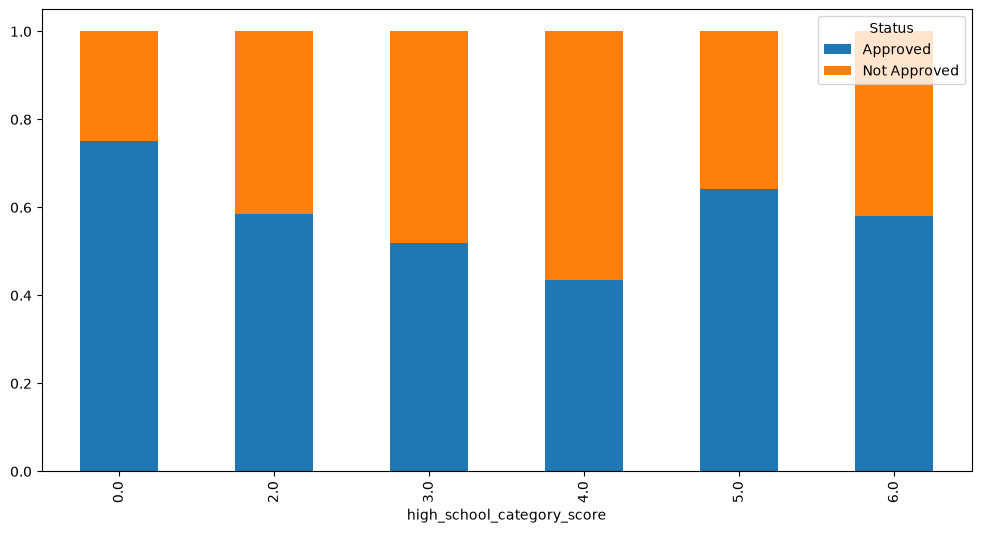

In [1145]:
Table1 = fa[['high_school_category_score', 'Status']]
value_counts = Table1.groupby('high_school_category_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, 
                  figsize=(12, 6))

In [1146]:
#show high school where highs school category is international 

fa[fa['High School Category'] == 'INTERNATIONAL']

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month,School,mean_grade_score,County Rate,High School Category,high_school_category_score
148,e61acf933f25,Female,Rophine Field International,B,2025,Machakos,Kenya,Both Parents,Jan-26,Diploma in International Relations FT,,2026-02-05 22:55:27,Approved,2026,2,SIMT,7.0,2.0,INTERNATIONAL,0.0
158,0fe3439ce90e,Male,Brookhurst International School,B,2024,Embu,Kenya,Both Parents,Jul-26,Bachelor of Business Information Technology,,2026-05-28 09:21:33,Approved,2026,5,SCES,7.0,4.0,INTERNATIONAL,0.0
996,e720c115ea7c,Male,British International School,B+,2023,Mombasa,Kenya,Father Deceased,Jul-24,Bachelor of Science in Informatics and Compute...,,2024-05-28 12:41:15,Approved,2024,5,SCES,8.0,1.0,INTERNATIONAL,0.0
1470,2b84df68b905,Male,Crawford International School Kenya,A-,2024,Nakuru,Kenya,Father Deceased,Jul-25,Bachelor of Science in Electrical and Electron...,,2026-02-05 11:18:35,Not Approved,2026,2,SCES,9.0,1.0,INTERNATIONAL,0.0


In [1147]:
fa

,ID,Gender,High School,Mean Grade,O LEVEL YEAR,County,Country,Parent Status,Intake,Course,Siblings,Date Applied,Status,Apply_Year,Apply_Month,School,mean_grade_score,County Rate,High School Category,high_school_category_score
0,6f20d326c544,Female,New Horizon Secondary,C+,2020,Nairobi,Kenya,Both Parents,Jan-26,Certified Public Accountant,,2026-01-13 12:35:40,Approved,2026,1,SIMT,5.0,1.0,PRIVATE,3.0
1,e552f3c9a4ca,Female,Vyulya Girls Sec,C,2016,Kitui,Kenya,Mother Deceased,Jan-26,Certified Public Accountant,,2026-01-15 16:32:19,Approved,2026,1,SIMT,2.0,4.0,SUB_COUNTY,6.0
2,2e91982af160,Female,Kabare Girls Secondary School,A,2025,Nairobi,Kenya,Both Parents,Jan-26,Diploma in Business Information Technology,,2026-02-04 10:33:58,Approved,2026,2,SIMT,10.0,1.0,SUB_COUNTY,6.0
3,583dd8ac280e,Male,Lenana School,B+,2025,Kiambu,Kenya,Both Parents,Jul-26,Bachelor of Science in Informatics and Compute...,,2026-04-24 10:08:50,Approved,2026,4,SCES,8.0,1.0,NATIONAL,2.0
4,155896ac7d72,Male,Laiser Hill Academy,B-,2025,Siaya,Kenya,Both Parents,Jul-26,Bachelor of Business Information Technology,,2026-06-19 15:15:32,Approved,2026,6,SCES,6.0,6.0,PRIVATE,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2317,40dd450deccf,Female,Kenya High Girls,A-,2021,Migori,Kenya,Both Parents,Jul-21,Bachelor of Laws,,2021-06-19 20:15:35,Not Approved,2021,6,SLS,9.0,5.0,NATIONAL,2.0
2318,64005080de35,Female,Aga Khan High school,B,2021,Mombasa,Kenya,Both Parents,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-06-25 17:36:55,Not Approved,2021,6,SCES,7.0,1.0,PRIVATE,3.0
2319,64005080de35,Female,Aga Khan High school,B,2021,Mombasa,Kenya,Both Parents,Jul-21,Bachelor of Science in Informatics and Compute...,,2021-06-25 17:36:55,Not Approved,2021,6,SCES,7.0,1.0,PRIVATE,3.0
2320,430c452ce031,Male,Maseno School,B+,2019,Kiambu,Kenya,Father Deceased,Jul-21,Bachelor of Laws,,2021-06-21 21:42:05,Not Approved,2021,6,SLS,8.0,1.0,NATIONAL,2.0


4. We will be prioritizing certain year compared to others

The rational here is to create a feature which gives priority to student have just completed their KCSE compared to the ones who completed the KCSE a little bit later.

The fresh KCSE candidates will be given more priority compared to someone who completed longtime ago.

In [1148]:
fa['O LEVEL YEAR'] = fa['O LEVEL YEAR'].astype('Int64')

In [1149]:
#first let group by Year and check the O level year distribution

gap = fa['Apply_Year'] - fa['O LEVEL YEAR']

conditions = [
    (gap <= 1),  # Gap of less than or equal to 1 year
    (gap == 2), #& (gap < 3),  # Gap between 2 and 3 years
    (gap == 3) , # & (gap < 4),  # Gap between 3 and 4 years
    (gap >= 4) & (gap <= 5),  # Gap between 4 and 5 years
    (gap >= 6)& (gap <= 7),  # Gap between 6 and 7 years
    (gap >= 8)  # Gap of 8 years or more
]
choices = [5, 4,3,2, 1,0]

fa["o_level_apply_score"] = np.select(
    conditions, choices, default=np.nan
)

In [1150]:
fa[['Apply_Year', 'O LEVEL YEAR', 'o_level_apply_score','Status']]

,Apply_Year,O LEVEL YEAR,o_level_apply_score,Status
0,2026,2020,1.0,Approved
1,2026,2016,0.0,Approved
2,2026,2025,5.0,Approved
3,2026,2025,5.0,Approved
4,2026,2025,5.0,Approved
...,...,...,...,...
2317,2021,2021,5.0,Not Approved
2318,2021,2021,5.0,Not Approved
2319,2021,2021,5.0,Not Approved
2320,2021,2019,4.0,Not Approved


<Axes: xlabel='o_level_apply_score'>

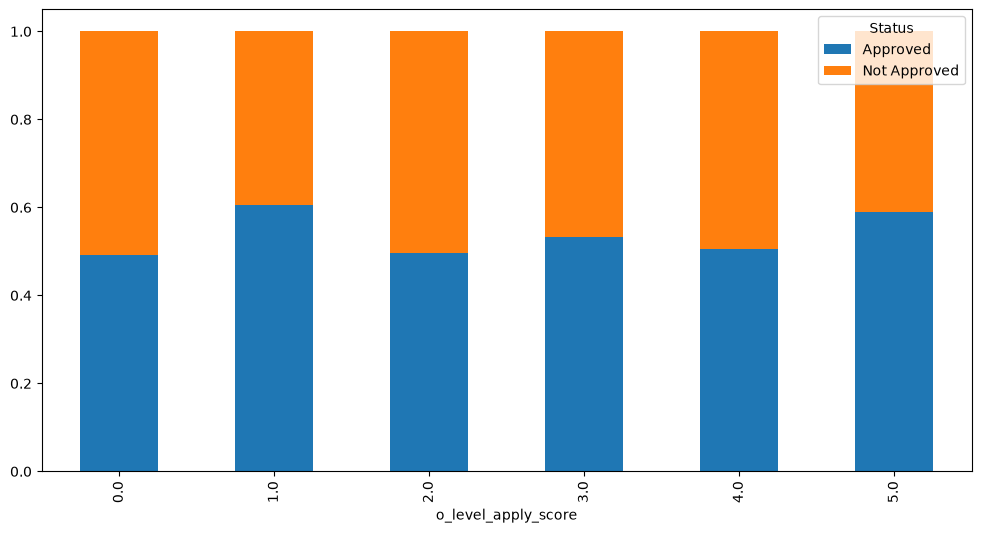

In [1151]:
Table2 = fa[['o_level_apply_score', 'Status']]
value_counts = Table2.groupby('o_level_apply_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=True, 
                  figsize=(12, 6))

5. Let create the parent status score

Both Parents with 1, Father Deceased and Mother Deceased 2 and orphan 3

In [1152]:
fa['parent_status_score'] = (
    fa['Parent Status'].map({
        'Both Parents': 1,
        'Father Deceased': 3,
        'Mother Deceased': 2,
        'Orphan': 4
    })
)

<Axes: xlabel='parent_status_score'>

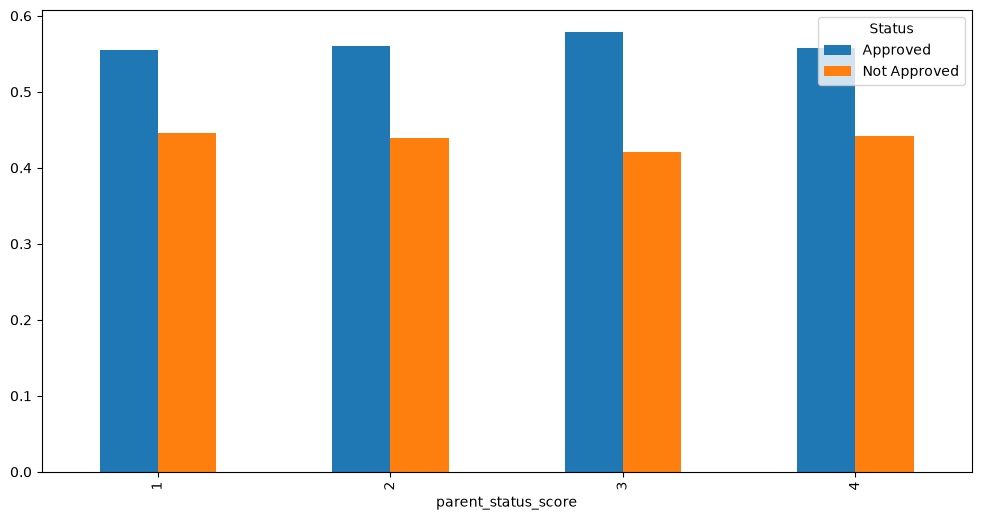

In [1153]:
Table1 = fa[['parent_status_score', 'Status']]
value_counts = Table1.groupby('parent_status_score')['Status'].value_counts(normalize=True).unstack().fillna(0)
value_counts.plot(kind='bar', stacked=False, 
                  figsize=(12, 6))

In [1154]:
fa[['Parent Status', 'parent_status_score']]

,Parent Status,parent_status_score
0,Both Parents,1
1,Mother Deceased,2
2,Both Parents,1
3,Both Parents,1
4,Both Parents,1
...,...,...
2317,Both Parents,1
2318,Both Parents,1
2319,Both Parents,1
2320,Father Deceased,3


Let create a rate for Course eligibility score where if undergraduate, diploma plus CPA we give a 1 if not a 0 

In [1155]:
# This is to help us create a feature for eligible or not based on 
# the course the student is doing. with if Degree, Diplomas + CPA = 1 otherwise give 0

import pandas as pd
import numpy as np
import re

# Work on a separate copy to preserve the original notebook
def classify_programme(course):
    if pd.isna(course) or not str(course).strip():
        return "Unclassified", None

    name = str(course).upper()
    name = re.sub(r"[.\-']", "", name)
    name = " ".join(name.split())

    # CPA remains eligible, including CPA certificates
    if re.search(
        r"\bCPA\b|CERTIFIED PUBLIC ACCOUNTANT", name
    ):
        return "CPA", 1

    # Master's programmes
    if re.search(
        r"\b(MASTER|MASTERS|MSC|MBA|LLM|MPHIL)\b",
        name
    ):
        return "Masters", 0

    # Postgraduate diplomas need separate policy verification
    if "POSTGRADUATE DIPLOMA" in name:
        return "Unclassified", None

    # Other certificates
    if re.search(r"\b(CERTIFICATE|Association of Chartered Certified Accountants)\b", name):
        return "Certificate", 0

    # Undergraduate degrees
    if re.search(
        r"\b(BACHELOR|BACHELORS|BSC|BCOM|BBIT|LLB|BBA)\b",
        name
    ):
        return "Undergraduate Degree", 1

    # Other professional qualifications
    other_professional_programmes = {
        "ASSOCIATION OF CHARTERED CERTIFIED ACCOUNTANTS",
        "CHARTERED FINANCIAL ANALYST",
        "CHARTERED INSTITUTE OF MARKETING"
    }

    if name in other_professional_programmes:
        return "Other Professional Qualification", 0

    # Diplomas
    if re.search(r"\bDIPLOMA\b", name):
        return "Diploma", 1

    return "Unclassified", None


fa[
    ["programme_level", "programme_eligible"]
] = pd.DataFrame(
    fa["Course"].apply(classify_programme).tolist(),
    index=fa.index
)

# Display programme classification
print("Programme distribution:")
display(fa["programme_level"].value_counts())

print("\nEligibility distribution:")
display(
    fa["programme_eligible"].value_counts(
        dropna=False
    )
)

# Inspect programmes requiring manual classification
print("\nUnclassified programmes:")
display(
    fa.loc[
        fa["programme_eligible"].isna(), "Course"
    ].value_counts()
)


Programme distribution:


programme_level
Undergraduate Degree                1812
Diploma                              303
CPA                                  179
Other Professional Qualification      16
Masters                               12
Name: count, dtype: int64


Eligibility distribution:


programme_eligible
1    2294
0      28
Name: count, dtype: int64


Unclassified programmes:


Series([], Name: count, dtype: int64)

In [1156]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2322 entries, 0 to 2321
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID                          2322 non-null   str           
 1   Gender                      2322 non-null   str           
 2   High School                 2315 non-null   str           
 3   Mean Grade                  2316 non-null   str           
 4   O LEVEL YEAR                2322 non-null   Int64         
 5   County                      2322 non-null   str           
 6   Country                     2322 non-null   str           
 7   Parent Status               2322 non-null   str           
 8   Intake                      2322 non-null   str           
 9   Course                      2322 non-null   str           
 10  Siblings                    2322 non-null   str           
 11  Date Applied                2322 non-null   datetime64[us]
 12  Sta

In [1157]:
fa['Course'].value_counts()

Course
Bachelor of Science in Informatics and Computer Science          341
Bachelor of Commerce                                             304
Bachelor of Business Information Technology                      262
Certified Public Accountant                                      179
Bachelor of Science in Electrical and Electronics Engineering    172
Diploma in Business Information Technology                       169
Bachelor of Laws                                                 139
Bsc. Computer Networks and Cybersecurity                          97
Bachelor of Arts International Studies                            94
Bachelor of Business Science in Financial Engineering             80
BSc. Statistics and Data Science (BSc. SDS)                       61
Diploma in International Relations FT                             56
Bachelor of Business Science in Financial Economics               53
Diploma in Business Management                                    50
Bachelor of Science in Hosp

In [1158]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2322 entries, 0 to 2321
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID                          2322 non-null   str           
 1   Gender                      2322 non-null   str           
 2   High School                 2315 non-null   str           
 3   Mean Grade                  2316 non-null   str           
 4   O LEVEL YEAR                2322 non-null   Int64         
 5   County                      2322 non-null   str           
 6   Country                     2322 non-null   str           
 7   Parent Status               2322 non-null   str           
 8   Intake                      2322 non-null   str           
 9   Course                      2322 non-null   str           
 10  Siblings                    2322 non-null   str           
 11  Date Applied                2322 non-null   datetime64[us]
 12  Sta

#### This will mark the end of our Features of importance. 

In [1159]:
fa['Status'] = fa['Status'].map({'Approved': 1, 'Not Approved': 0})

<Axes: >

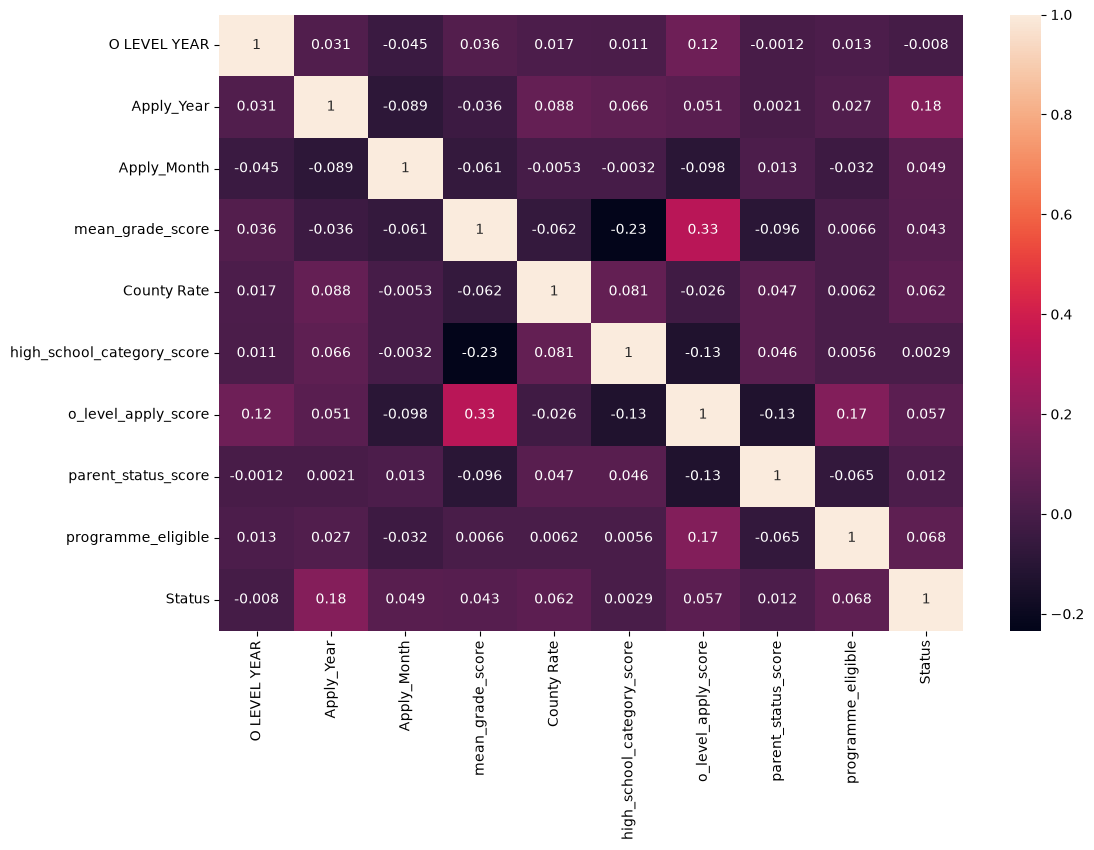

In [1160]:
corr = fa.select_dtypes(include='number').corr()

cols = [c for c in corr.columns if c != 'Status'] + ['Status']
corr = corr.loc[cols, cols]

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=corr,
    annot=True,
)

In [1161]:
fa.info()

<class 'pandas.DataFrame'>
RangeIndex: 2322 entries, 0 to 2321
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   ID                          2322 non-null   str           
 1   Gender                      2322 non-null   str           
 2   High School                 2315 non-null   str           
 3   Mean Grade                  2316 non-null   str           
 4   O LEVEL YEAR                2322 non-null   Int64         
 5   County                      2322 non-null   str           
 6   Country                     2322 non-null   str           
 7   Parent Status               2322 non-null   str           
 8   Intake                      2322 non-null   str           
 9   Course                      2322 non-null   str           
 10  Siblings                    2322 non-null   str           
 11  Date Applied                2322 non-null   datetime64[us]
 12  Sta

In [1162]:
fa['programme_eligible'].value_counts()

programme_eligible
1    2294
0      28
Name: count, dtype: int64

In [1163]:
# Retain the original dataset
fa_all = fa.copy()

# Train the model on eligible programmes only
fa = fa.loc[
    fa["programme_eligible"] == 1
].copy()

print("=== ELIGIBLE TRAINING POPULATION ===")
print("Original records:", len(fa_all))
print("Eligible records:", len(fa))
print("Excluded records:", len(fa_all) - len(fa))

print("\nHistorical outcomes:")
print(fa["Status"].value_counts())

=== ELIGIBLE TRAINING POPULATION ===
Original records: 2322
Eligible records: 2294
Excluded records: 28

Historical outcomes:
Status
1    1287
0    1007
Name: count, dtype: int64


1. Let separate the train and target variables. 

In [1286]:
X = fa.drop(columns=['ID', 'Gender', 'High School', 
             #'Mean Grade', 
             #'O LEVEL YEAR', #'County',
             'Country', 
             #'Parent Status', 
             'Intake', 
             'Course', 'Siblings','Date Applied', 'Status', 
             #'Apply_Year', 
             'Apply_Month', 
             'School', #'mean_grade_score', 'County Rate', 'High School Category',
             #'high_school_category_score', 
             #'o_level_apply_score', 
             #'parent_status_score',
             'programme_level',
             #'programme_eligible'

    ]
)

y = fa['Status']
'''

X = fa.drop(columns=['ID', 'Gender', 'High School', 
             #'Mean Grade', 
             #'O LEVEL YEAR', #'County',
             'Country', 
             #'Parent Status', 
             'Intake', 
             'Course', 'Siblings','Date Applied', 'Status', 
             #'Apply_Year', 
             'Apply_Month', 
             'School', #'mean_grade_score', 'County Rate', 'High School Category',
             #'high_school_category_score', 
             #'o_level_apply_score', 
             #'parent_status_score',
             'programme_level',
             #'programme_eligible'

    ]
)

y = fa['Status']'''

"\n\nX = fa.drop(columns=['ID', 'Gender', 'High School', \n             #'Mean Grade', \n             #'O LEVEL YEAR', #'County',\n             'Country', \n             #'Parent Status', \n             'Intake', \n             'Course', 'Siblings','Date Applied', 'Status', \n             #'Apply_Year', \n             'Apply_Month', \n             'School', #'mean_grade_score', 'County Rate', 'High School Category',\n             #'high_school_category_score', \n             #'o_level_apply_score', \n             #'parent_status_score',\n             'programme_level',\n             #'programme_eligible'\n\n    ]\n)\n\ny = fa['Status']"

In [1287]:
# Since we have o level year, apply year and o level apply year score, 
# we can drop the o level year and apply year 
# since they helped us get the o level apply year score.

X = X.drop(columns=['County', 'Mean Grade'])

In [1288]:
numerical_cols = X.select_dtypes(include='number').columns
categorical_cols = X.select_dtypes(include='object').columns

print(f'Numerical Columns: {list(numerical_cols)}')
print(f'Categorical Columns: {list(categorical_cols)}')

Numerical Columns: ['O LEVEL YEAR', 'Apply_Year', 'mean_grade_score', 'County Rate', 'high_school_category_score', 'o_level_apply_score', 'parent_status_score', 'programme_eligible']
Categorical Columns: ['Parent Status', 'High School Category']


C:\Users\user\AppData\Local\Temp\ipykernel_31868\2421744389.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include='object').columns


**Let Create a Pipeline**

In [1289]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (RobustScaler,
                                   OneHotEncoder
                                   )

from sklearn.impute import SimpleImputer


# create data types 

#numerical cols 

numerical_pipelines = Pipeline(steps=[
    ('num_imputer', SimpleImputer(strategy='median')),
    ('num_scaler', RobustScaler())
])

#Categorical cols 

categorical_pipelines = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

transformer = ColumnTransformer(transformers=[
    ('num', numerical_pipelines, numerical_cols),
    ('cat', categorical_pipelines, categorical_cols)
])

transformer

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [1290]:
# LEt audit our cell before splitting
# Audit repeated applications for the same ID and Course

duplicate_records = fa[
    fa.duplicated(
        subset=["ID", "Course"],
        keep=False
    )
].copy()

# Summarize repeated ID + Course combinations
duplicate_summary = (
    duplicate_records
    .groupby(["ID", "Course"], dropna=False)
    .agg(
        Records=("Status", "size"),
        Different_Outcomes=("Status", "nunique"),
        Different_Dates=("Date Applied", "nunique")
    )
    .reset_index()
    .sort_values("Records", ascending=False)
)

print("Repeated ID + Course combinations:",
      len(duplicate_summary))

print("Conflicting outcomes:",
      (duplicate_summary["Different_Outcomes"] > 1).sum())

print("Exact duplicate rows:",
      fa.duplicated().sum())

display(duplicate_summary)


Repeated ID + Course combinations: 28
Conflicting outcomes: 0
Exact duplicate rows: 53


,ID,Course,Records,Different_Outcomes,Different_Dates
0,1573b4ebebe0,Bachelor of Science in Informatics and Compute...,3,1,1
1,18e9a0ca8557,Bachelor of Laws,3,1,1
2,281fde618d05,Bachelor of Business Science in Financial Econ...,3,1,1
4,4542794b1470,Bachelor of Laws,3,1,1
8,5b61e287ca28,Bachelor of Science in Informatics and Compute...,3,1,1
5,459901248494,BSc. Statistics and Data Science (BSc. SDS),3,1,1
6,56045f5c1cb9,Bachelor of Laws,3,1,1
7,57960d9bea4c,Bachelor of Laws,3,1,1
10,5d73b4b332b7,Bachelor of Science in Informatics and Compute...,3,1,1
9,5b914def163d,Bachelor of Business Information Technology,3,1,1


In [1291]:
# We will replace our previous random split with group splitting 

'''from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)'''


from sklearn.model_selection import StratifiedGroupKFold

# ====================================================
# 1. ALIGN FEATURES, TARGET AND STUDENT IDS
# ====================================================

assert len(X) == len(y) == len(fa), (
    "X, y and fa must contain the same records."
)

# These X and y were constructed from fa
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

groups = (
    fa["ID"]
    .astype("string")
    .str.strip()
    .reset_index(drop=True)
)

if groups.isna().any() or groups.eq("").any():
    raise ValueError("Missing Student IDs detected.")

# ====================================================
# 2. STRATIFIED GROUP-AWARE SPLIT
# ====================================================

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

# Create training and testing datasets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# ====================================================
# 3. VERIFY NO STUDENT OVERLAP
# ====================================================

train_students = set(groups.iloc[train_idx])
test_students = set(groups.iloc[test_idx])

overlap = train_students.intersection(test_students)

print("GROUP-AWARE TRAIN / TEST SPLIT")
print("-" * 40)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Unique training students:", len(train_students))
print("Unique testing students:", len(test_students))

print("Overlapping Student IDs:", len(overlap))

print("\nTraining approval rate:",
      round(y_train.mean(), 4))

print("Testing approval rate:",
      round(y_test.mean(), 4))

assert len(overlap) == 0, (
    "Data leakage: Student IDs overlap!"
)

print("\nGroup-aware split validation PASSED.")



GROUP-AWARE TRAIN / TEST SPLIT
----------------------------------------
Training records: 1835
Testing records: 459
Unique training students: 1683
Unique testing students: 426
Overlapping Student IDs: 0

Training approval rate: 0.5608
Testing approval rate: 0.5621

Group-aware split validation PASSED.


Now that we have split our data let transform the data

In [1292]:
X_transformed = transformer.fit_transform(X_train)
X_test_transformed = transformer.transform(X_test)



SInce we have finalizing transforming our data set, let onw go ahead and 

**train our models.** 



1. We will train using Logist regression and will be used as our baseline model. 


In [1293]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)

lr_model.fit(X_transformed, y_train) #Training
lr_model

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [1294]:
# Let evaluate the Logistic Regression model 
from sklearn.metrics import classification_report, confusion_matrix, f1_score 

y_pred_lr = lr_model.predict(X_test_transformed)

In [1295]:
f1_score(y_test, y_pred_lr)

0.6946308724832215

In [1296]:
print(confusion_matrix(y_test, y_pred_lr))

[[ 70 131]
 [ 51 207]]


In [1297]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.58      0.35      0.43       201
           1       0.61      0.80      0.69       258

    accuracy                           0.60       459
   macro avg       0.60      0.58      0.56       459
weighted avg       0.60      0.60      0.58       459



In [1298]:
lr_df= pd.DataFrame(lr_model.coef_[0], 
                   columns=['importance'], 
                   index=transformer.get_feature_names_out())
lr_df.sort_values(by='importance', ascending=False).head(10)

,importance
cat__High School Category_SUB_COUNTY,0.589639
num__Apply_Year,0.420936
cat__High School Category_COUNTY,0.336530
num__parent_status_score,0.138757
num__County Rate,0.131907
num__mean_grade_score,0.076187
cat__Parent Status_Orphan,0.067022
cat__Parent Status_Both Parents,0.064963
num__o_level_apply_score,0.040758
num__O LEVEL YEAR,0.037896


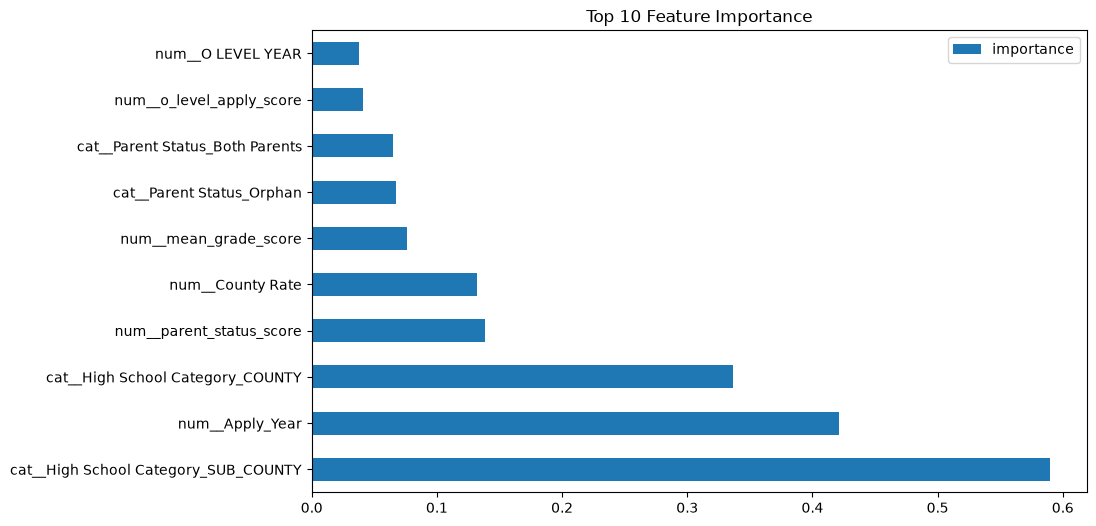

In [1299]:
lr_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

2. We will train using Random Forest and Logistic regression and compare the best model 

In [1300]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_transformed, y_train) #Training
rf_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Since we have train the Random Forest 

Let now evaluate the classifier

In [1301]:
#evaluation of the model 



y_pred_rf = rf_model.predict(X_test_transformed)

In [1302]:
f1_score(y_test, y_pred_rf)

0.6487523992322457

In [1303]:
print(confusion_matrix(y_test, y_pred_rf))

[[107  94]
 [ 89 169]]


In [1304]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.55      0.53      0.54       201
           1       0.64      0.66      0.65       258

    accuracy                           0.60       459
   macro avg       0.59      0.59      0.59       459
weighted avg       0.60      0.60      0.60       459



In [1305]:
rf_df= pd.DataFrame(rf_model.feature_importances_, 
                   columns=['importance'], 
                   index=transformer.get_feature_names_out())
rf_df.sort_values(by='importance', ascending=False)

,importance
num__mean_grade_score,0.297214
num__County Rate,0.209021
num__O LEVEL YEAR,0.144761
num__Apply_Year,0.120772
num__o_level_apply_score,0.084470
num__high_school_category_score,0.038793
num__parent_status_score,0.019160
cat__High School Category_PRIVATE,0.016473
cat__High School Category_NATIONAL,0.013799
cat__Parent Status_Both Parents,0.012263


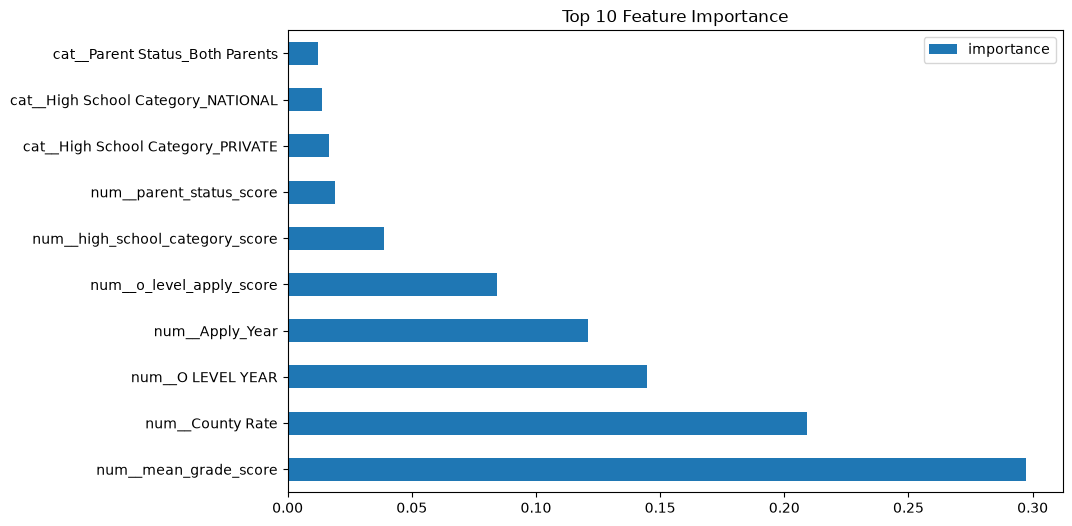

In [1306]:
rf_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

3. XGBoost 

Let train XGBOost

In [1307]:
#let train xgboost model

from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42)

xgb_model.fit(X_transformed, y_train)
xgb_model

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [1308]:
#Let evaluate the XGBoost model

y_pred_xgb = xgb_model.predict(X_test_transformed)


In [1309]:
f1_score(y_test, y_pred_xgb)

0.6341463414634146

In [1310]:
print(confusion_matrix(y_test, y_pred_xgb))

[[ 95 106]
 [ 89 169]]


In [1311]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.52      0.47      0.49       201
           1       0.61      0.66      0.63       258

    accuracy                           0.58       459
   macro avg       0.57      0.56      0.56       459
weighted avg       0.57      0.58      0.57       459



In [1312]:
xgb_df= pd.DataFrame(xgb_model.feature_importances_, 
                   columns=['importance'], 
                   index=transformer.get_feature_names_out())
xgb_df.sort_values(by='importance', ascending=False).head(10)

,importance
num__Apply_Year,0.130194
num__mean_grade_score,0.107511
cat__High School Category_PRIVATE,0.095703
num__parent_status_score,0.085375
num__high_school_category_score,0.084082
num__County Rate,0.080184
cat__High School Category_NATIONAL,0.077128
num__O LEVEL YEAR,0.073380
num__o_level_apply_score,0.071536
cat__Parent Status_Mother Deceased,0.066170


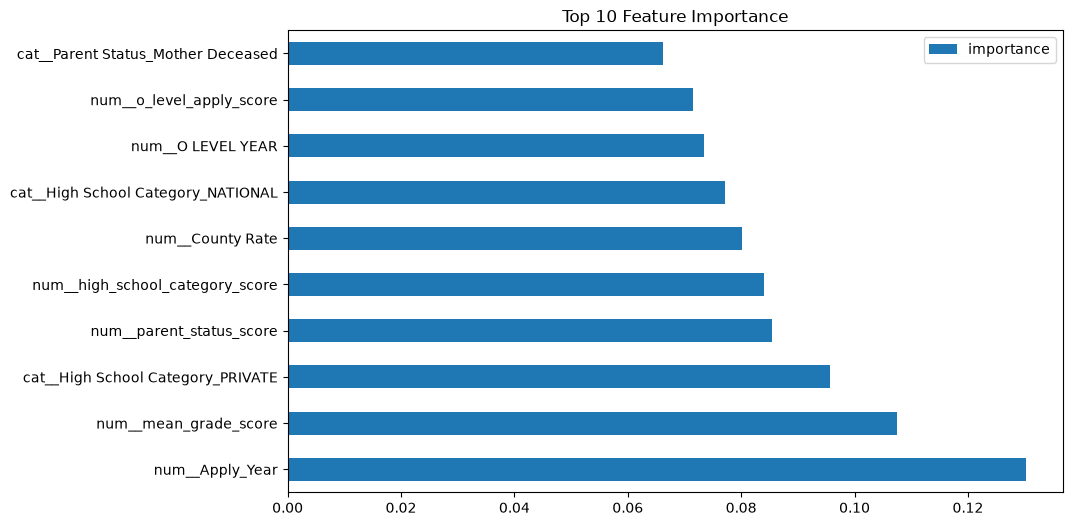

In [1313]:
xgb_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

4. Gradient Boost

In [1314]:
#let train gradient boost

from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_transformed, y_train)

gb_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [1315]:
#Let evaluate the Gradient model

y_pred_gb = gb_model.predict(X_test_transformed)

In [1316]:
f1_score(y_test, y_pred_gb)

0.6979166666666666

In [1317]:
print(confusion_matrix(y_test, y_pred_gb))

[[ 84 117]
 [ 57 201]]


In [1318]:
print(classification_report(y_test, y_pred_gb))

              precision    recall  f1-score   support

           0       0.60      0.42      0.49       201
           1       0.63      0.78      0.70       258

    accuracy                           0.62       459
   macro avg       0.61      0.60      0.59       459
weighted avg       0.62      0.62      0.61       459



In [1319]:
gb_df= pd.DataFrame(gb_model.feature_importances_, 
                   columns=['importance'], 
                   index=transformer.get_feature_names_out())
gb_df.sort_values(by='importance', ascending=False).head(10)

,importance
num__mean_grade_score,0.268313
num__Apply_Year,0.252636
num__O LEVEL YEAR,0.145386
num__high_school_category_score,0.071250
num__County Rate,0.059458
cat__High School Category_PRIVATE,0.044141
num__o_level_apply_score,0.038075
num__parent_status_score,0.027459
cat__High School Category_UNKNOWN,0.021232
cat__High School Category_SUB_COUNTY,0.020396


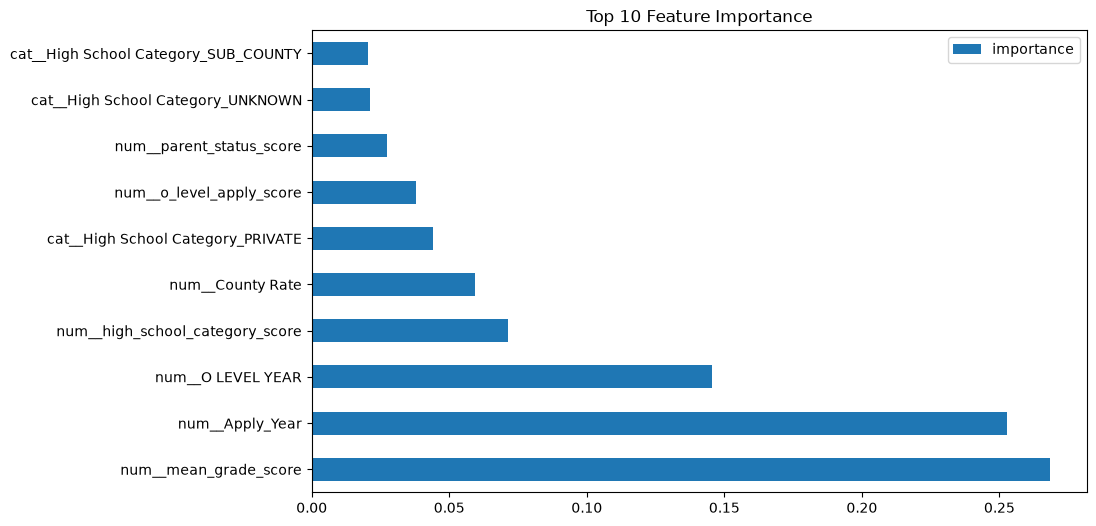

In [1320]:
gb_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

#### Model Comparison

In [1321]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

def evaluate(name, model, X_t, y_t):
    y_pred = model.predict(X_t)
    y_prob = model.predict_proba(X_t)[:,1]
    print(f"\n=== {name} ===")
    print(f" Accuracy  : {accuracy_score(y_t, y_pred):.4f}")
    print(f" Precision : {precision_score(y_t, y_pred, zero_division=0):.4f}")
    print(f"  Recall   : {recall_score(y_t, y_pred, zero_division=0):.4f}")
    print(f"  F1 Score : {f1_score(y_t, y_pred, zero_division=0):.4f}")
    print(f"  AUC-ROC  : {roc_auc_score(y_t, y_prob):.4f}")
    return y_pred






lr_preds = evaluate("Logistic Regression", lr_model, X_test_transformed, y_test)
rf_preds = evaluate("Random Forest", rf_model, X_test_transformed, y_test)
xgb_preds = evaluate("XGBoost", xgb_model, X_test_transformed, y_test)
gradient_preds = evaluate("Gradient Boosting", gb_model, X_test_transformed, y_test)
#svm_preds = evaluate("SVM", svm_model, X_test_transformed, y_test)
#lgbm_preds = evaluate("LightGBM", lightgbm_model, X_test_transformed, y_test)
#catboost_preds = evaluate("CatBoost", catboost_model, X_test_transformed, y_test)
#decisiontree_preds = evaluate("Decision Tree", decisiontree_model, X_test_transformed, y_test)
#naivebayes_preds = evaluate("Naive Bayes", naivebayes_model, X_test_transformed, y_test)



=== Logistic Regression ===
 Accuracy  : 0.6035
 Precision : 0.6124
  Recall   : 0.8023
  F1 Score : 0.6946
  AUC-ROC  : 0.6267

=== Random Forest ===
 Accuracy  : 0.6013
 Precision : 0.6426
  Recall   : 0.6550
  F1 Score : 0.6488
  AUC-ROC  : 0.6262

=== XGBoost ===
 Accuracy  : 0.5752
 Precision : 0.6145
  Recall   : 0.6550
  F1 Score : 0.6341
  AUC-ROC  : 0.5979

=== Gradient Boosting ===
 Accuracy  : 0.6209
 Precision : 0.6321
  Recall   : 0.7791
  F1 Score : 0.6979
  AUC-ROC  : 0.6559


Let Plot these models

In [1322]:
#Model definitions : 

models_config = [ 
    {
        "name" : "Logistic Regression", 
        "model": lr_model, 
        "X": X_test_transformed, 
        "y" : y_test    
    },
    {
        "name" : "Random Forest",
        "model": rf_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "XGBoost",
        "model": xgb_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "Gradient Boosting",
        "model": gb_model,
        "X": X_test_transformed, 
        "y": y_test
    }
]
'''{
        "name" : "SVM",
        "model": svm_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "LightGBM",
        "model": lightgbm_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "CatBoost",
        "model": catboost_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "Decision Tree",
        "model": decisiontree_model,
        "X": X_test_transformed, 
        "y": y_test
    },
    {
        "name" : "Naive Bayes",
        "model": naivebayes_model,
        "X": X_test_transformed, 
        "y": y_test
    }
]'''


'{\n        "name" : "SVM",\n        "model": svm_model,\n        "X": X_test_transformed, \n        "y": y_test\n    },\n    {\n        "name" : "LightGBM",\n        "model": lightgbm_model,\n        "X": X_test_transformed, \n        "y": y_test\n    },\n    {\n        "name" : "CatBoost",\n        "model": catboost_model,\n        "X": X_test_transformed, \n        "y": y_test\n    },\n    {\n        "name" : "Decision Tree",\n        "model": decisiontree_model,\n        "X": X_test_transformed, \n        "y": y_test\n    },\n    {\n        "name" : "Naive Bayes",\n        "model": naivebayes_model,\n        "X": X_test_transformed, \n        "y": y_test\n    }\n]'

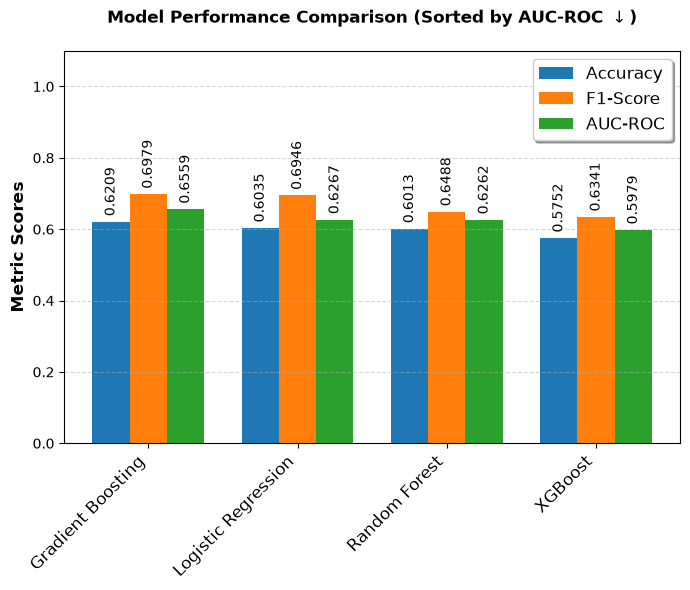

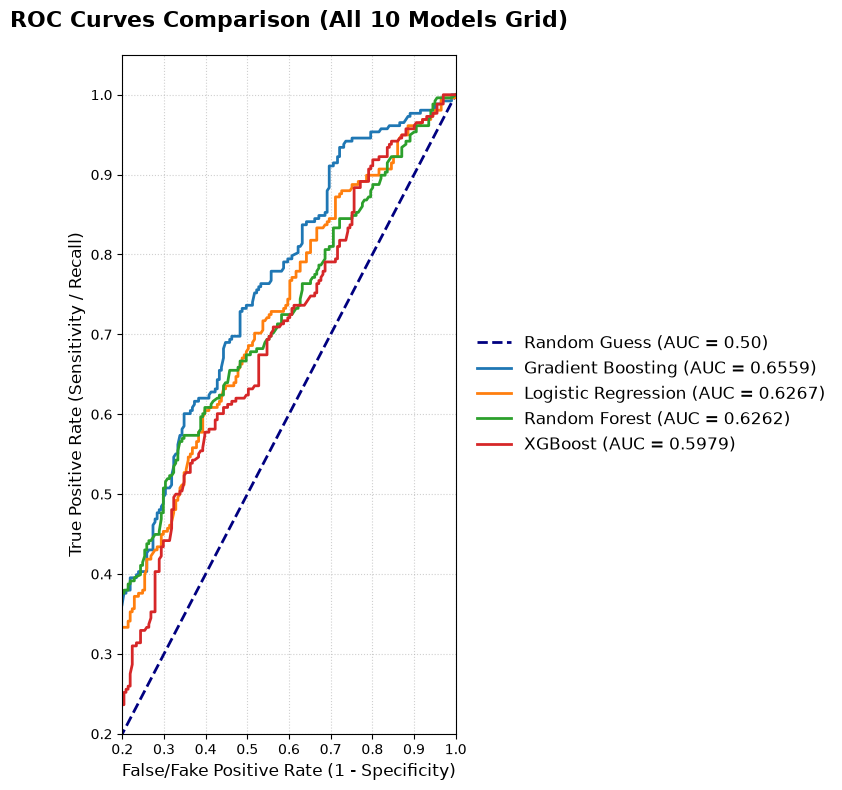

In [1323]:
# 2. Extract metrics and ROC curve data
metrics_list = []
roc_curves_data = {}

for cfg in models_config:
    name = cfg["name"]
    model = cfg["model"]
    X_test = cfg["X"]
    y_test = cfg["y"]

    # Generate predictions and probabilities matching your evaluate function
    # Align X_test with the feature names the model was trained on
    if hasattr(model, "feature_names_in_") and isinstance(X_test, pd.DataFrame):
        X_test = X_test.reindex(columns=model.feature_names_in_, fill_value=0)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    

    # Calculate target comparison metrics
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    metrics_list.append(
        {"Model": name, "Accuracy": acc, "F1-Score": f1, "AUC-ROC": auc}
    )

    # Save ROC curve coordinates
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_curves_data[name] = (fpr, tpr, auc)

# Convert metrics to a DataFrame and sort by AUC-ROC descending for optimal visualization
df_metrics = pd.DataFrame(metrics_list).sort_values(
    by="AUC-ROC", ascending=False
)


# =====================================================================
# VISUALIZATION 1: Side-by-Side Grouped Bar Chart
# =====================================================================
models = df_metrics["Model"].tolist()
x = np.arange(len(models))  # Label locations
width = 0.25  # Width of each metric bar

fig, ax = plt.subplots(figsize=(7, 6))

# Plot the 3 core comparison metrics side-by-side
rects1 = ax.bar(
    x - width, df_metrics["Accuracy"], width, label="Accuracy", color="#1f77b4"
)
rects2 = ax.bar(x, df_metrics["F1-Score"], width, label="F1-Score", color="#ff7f0e")
rects3 = ax.bar(
    x + width, df_metrics["AUC-ROC"], width, label="AUC-ROC", color="#2ca02c"
)

# Style axes and titles to ensure high readability
ax.set_ylabel("Metric Scores", fontsize=12, fontweight="bold")
ax.set_title(
    "Model Performance Comparison (Sorted by AUC-ROC $\\downarrow$)",
    fontsize=12,
    fontweight="bold",
    pad=20,
)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha="right", fontsize=12)
ax.set_ylim(0, 1.1)  # Extra headroom for labels
ax.legend(loc="upper right", fontsize=12, shadow=True)
ax.grid(axis="y", linestyle="--", alpha=0.5)


# Helper function to place value labels vertically above each bar to prevent overlap
def annotate_bars(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f"{height:.4f}",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 4),  # 4 points vertical offset
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            rotation=90,
        )


annotate_bars(rects1)
annotate_bars(rects2)
annotate_bars(rects3)

plt.tight_layout()
#plt.savefig("model_metrics_comparison.png", dpi=300)
#print("Saved: 'model_metrics_comparison.png'")


# =====================================================================
# VISUALIZATION 2: Combined ROC Curve Plot
# =====================================================================
fig, ax = plt.subplots(figsize=(8, 8))

# Plot baseline random guess line
ax.plot(
    [0, 1],
    [0, 1],
    color="navy",
    lw=2,
    linestyle="--",
    label="Random Guess (AUC = 0.50)",
)

# Plot each model's ROC curve using the same descending order from the bar chart
for name in models:
    fpr, tpr, auc = roc_curves_data[name]
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.4f})")

# Format details for professional appearance
ax.set_xlim([0.2, 1.0])
ax.set_ylim([0.2, 1.05])
ax.set_xlabel("False/Fake Positive Rate (1 - Specificity)", fontsize=12)
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
ax.set_title(
    "ROC Curves Comparison (All 10 Models Grid)",
    fontsize=16,
    fontweight="bold",
    pad=20,
)

# Place the legend cleanly outside the main axis box so lines are never covered
ax.legend(
    loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=12, frameon=False
)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
#plt.savefig("model_roc_curves.png", dpi=300)
#print("Saved: 'model_roc_curves.png'")

In [1324]:
gb_model 

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

#### Let create a dictionary

In [1325]:
model_artifacts = {
    "model_name": "Gradient Boosting Classifier",
    "model": gb_model,
    "model_pipeline": transformer,
    "version": "1.0",
    "author": "Julien Ngalo 2026",
}

In [1326]:
type(model_artifacts)

dict

In [1327]:
import joblib 

joblib.dump(
    model_artifacts,
    'awards'

)

['awards']

In [1328]:
#feature importance 

gb_df

,importance
num__O LEVEL YEAR,0.145386
num__Apply_Year,0.252636
num__mean_grade_score,0.268313
num__County Rate,0.059458
num__high_school_category_score,0.071250
num__o_level_apply_score,0.038075
num__parent_status_score,0.027459
num__programme_eligible,0.000000
cat__Parent Status_Both Parents,0.004896
cat__Parent Status_Father Deceased,0.003190


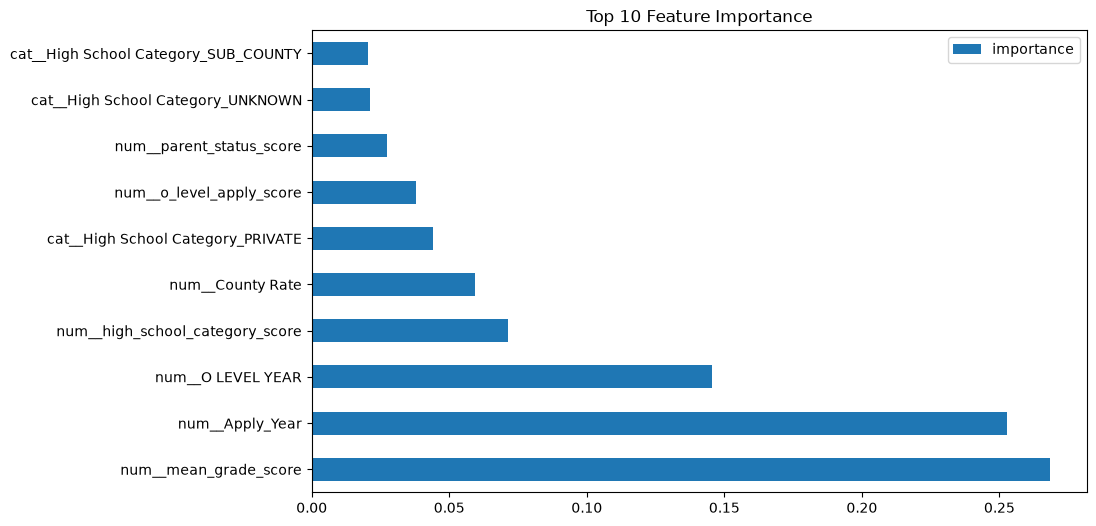

In [1329]:
gb_df.sort_values(by='importance',ascending=False).head(10).plot(kind='barh',figsize=(10,6),title='Top 10 Feature Importance');

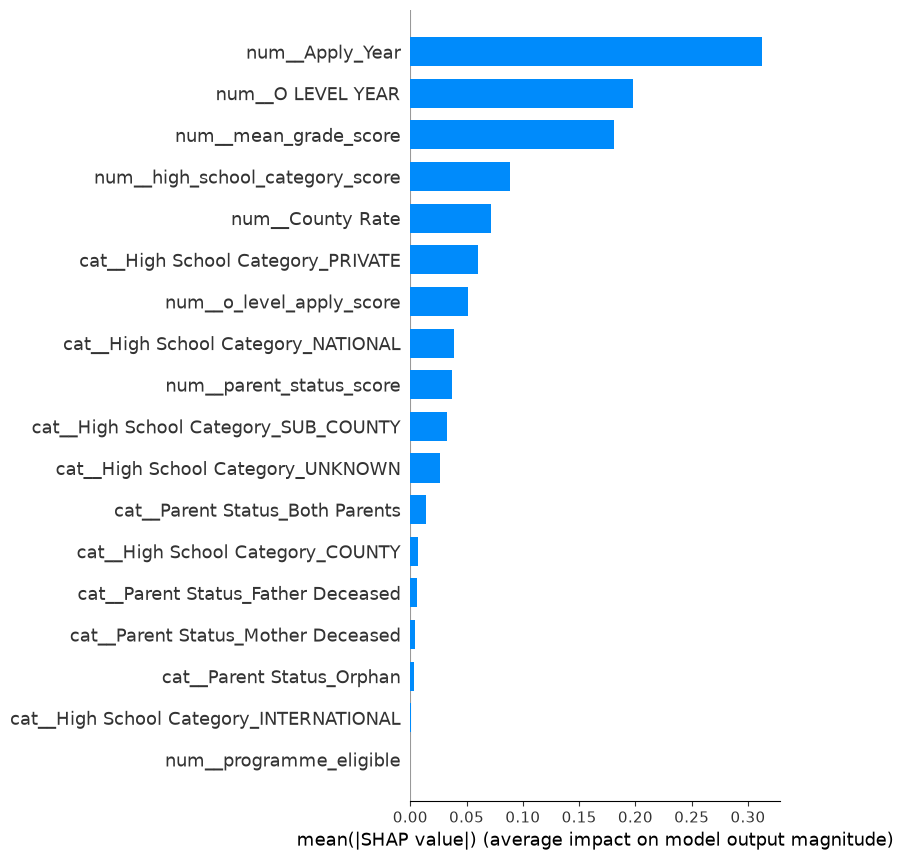

In [1330]:
# Model Explainability for Gradient Boosting

import shap

feature_names = transformer.get_feature_names_out()


explainer = shap.TreeExplainer(gb_model)

shap_values = explainer.shap_values(X_test_transformed)

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type='bar'
)



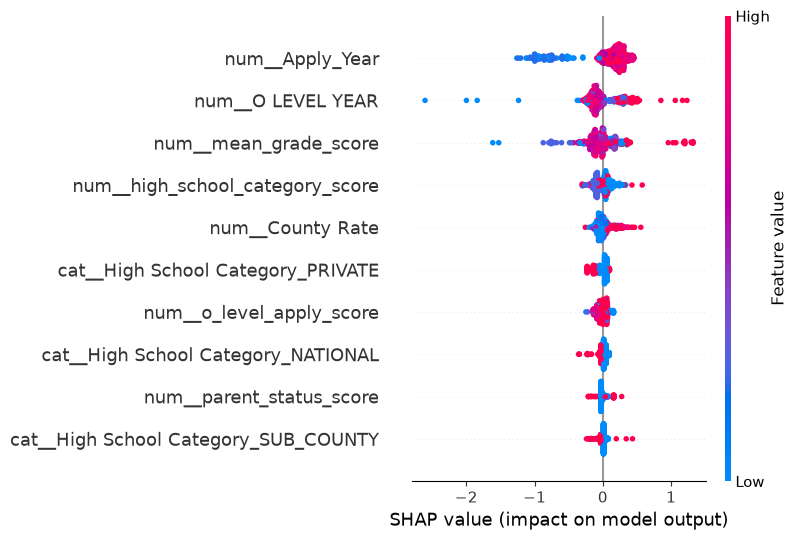

In [1331]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    max_display=10
)

#### Fainess Evaluation Metrics 

In [1332]:

import pandas as pd
import numpy as np

# Recover test applicant characteristics
fairness_test = fa.iloc[test_idx][[
    "County",
    "Parent Status",
    "High School Category"
]].copy().reset_index(drop=True)

# Actual outcomes from group-aware test
fairness_test["Actual"] = np.asarray(y_test)

# Model predictions
fairness_test["Predicted"] = gb_model.predict(
    X_test_transformed
)

# Predicted approval probabilities
fairness_test["Approval_Probability"] = (
    gb_model.predict_proba(
        X_test_transformed
    )[:, 1]
)

# Confirm alignment
assert len(fairness_test) == len(y_test)

assert np.array_equal(
    fairness_test["Actual"].to_numpy(),
    fa.iloc[test_idx]["Status"].to_numpy()
), "Test rows and labels are not aligned."

assert set(fairness_test["Actual"].unique()).issubset({0, 1})

print("=== FAIRNESS EVALUATION DATASET ===")
print("Total test applicants:", len(fairness_test))

print("\nActual outcomes:")
print(fairness_test["Actual"].value_counts())

print("\nPredicted outcomes:")
print(fairness_test["Predicted"].value_counts())

print("\nAvailable fairness groups:")
print(fairness_test[[
    "County",
    "Parent Status",
    "High School Category"
]].nunique())


=== FAIRNESS EVALUATION DATASET ===
Total test applicants: 459

Actual outcomes:
Actual
1    258
0    201
Name: count, dtype: int64

Predicted outcomes:
Predicted
1    318
0    141
Name: count, dtype: int64

Available fairness groups:
County                  42
Parent Status            4
High School Category     6
dtype: int64


##### Let calculate Subgroup fairness Metrics

In [1333]:

from sklearn.metrics import confusion_matrix

def subgroup_fairness(data, group_column, min_size=20):
    results = []

    for group, subset in data.groupby(
        group_column, dropna=False
    ):
        n = len(subset)

        tn, fp, fn, tp = confusion_matrix(
            subset["Actual"],
            subset["Predicted"],
            labels=[0, 1]
        ).ravel()

        n_positive = tp + fn
        n_negative = tn + fp

        # Suppress small groups and groups with
        # insufficient actual outcomes
        if n < min_size or min(n_positive, n_negative) < 5:
            continue

        results.append({
            "Group": str(group),
            "Applicants": n,
            "Actual Approval Rate":
                subset["Actual"].mean(),
            "Predicted Approval Rate":
                subset["Predicted"].mean(),
            "Recall (TPR)": tp / n_positive,
            "FNR": fn / n_positive,
            "FPR": fp / n_negative,
            "Precision":
                tp / (tp + fp)
                if (tp + fp) > 0 else np.nan
        })

    return pd.DataFrame(results).sort_values(
        "Applicants", ascending=False
    ) if results else pd.DataFrame()


county_fairness = subgroup_fairness(
    fairness_test, "County"
)

parent_fairness = subgroup_fairness(
    fairness_test, "Parent Status"
)

school_fairness = subgroup_fairness(
    fairness_test, "High School Category"
)

print("=== FAIRNESS BY COUNTY ===")
display(county_fairness.round(3))

print("\n=== FAIRNESS BY PARENT STATUS ===")
display(parent_fairness.round(3))

print("\n=== FAIRNESS BY HIGH SCHOOL CATEGORY ===")
display(school_fairness.round(3))


=== FAIRNESS BY COUNTY ===


,Group,Applicants,Actual Approval Rate,Predicted Approval Rate,Recall (TPR),FNR,FPR,Precision
2,Nairobi,160,0.550,0.631,0.750,0.250,0.486,0.653
1,Kiambu,41,0.561,0.659,0.696,0.304,0.611,0.593
0,Kakamega,22,0.364,0.727,0.875,0.125,0.643,0.438



=== FAIRNESS BY PARENT STATUS ===


,Group,Applicants,Actual Approval Rate,Predicted Approval Rate,Recall (TPR),FNR,FPR,Precision
0,Both Parents,389,0.566,0.689,0.768,0.232,0.586,0.631
1,Father Deceased,48,0.583,0.708,0.786,0.214,0.600,0.647



=== FAIRNESS BY HIGH SCHOOL CATEGORY ===


,Group,Applicants,Actual Approval Rate,Predicted Approval Rate,Recall (TPR),FNR,FPR,Precision
0,NATIONAL,181,0.564,0.751,0.843,0.157,0.633,0.632
1,PRIVATE,126,0.540,0.492,0.632,0.368,0.328,0.694
2,SUB_COUNTY,114,0.605,0.833,0.899,0.101,0.733,0.653
3,nan,20,0.450,0.850,0.889,0.111,0.818,0.471


1. Subgroup Fairness Analysis

A. Fairness by County

The county-level assessment revealed variations in model performance across Nairobi, Kiambu, and Kakamega. Kiambu recorded the highest False Negative Rate (FNR) at 34.8%, followed by Nairobi at 23.9% and Kakamega at 12.5%. Conversely, Kakamega recorded the highest False Positive Rate (FPR) at 71.4%, indicating that the model frequently predicted approval for historically unsuccessful applicants. The results suggest inconsistent classification performance across counties. However, the small samples for Kiambu (41) and Kakamega (22), together with the exclusion of other counties that did not meet the reporting thresholds, limit the generalisability of these findings.

B. Fairness by Parent Status

The parental-status analysis showed relatively modest differences in false-negative rates. Applicants with Both Parents recorded an FNR of 25.5%, compared with 21.4% for applicants whose fathers were deceased. However, the Father Deceased group recorded a higher FPR (70.0%) than the Both Parents group (59.8%). These findings indicate some variation in classification errors, although the smaller sample for the Father Deceased group (48 applicants) and the exclusion of other parental-status categories limit the conclusions that can be drawn.

C. Fairness by High School Category

The high-school category analysis identified the highest FNR among PRIVATE-school applicants (30.9%), compared with SUB_COUNTY (18.8%) and NATIONAL (16.7%). PRIVATE-school applicants also recorded a lower predicted approval rate (57.1%) than NATIONAL (75.7%) and SUB_COUNTY (75.4%) applicants. Conversely, NATIONAL and SUB_COUNTY schools recorded higher FPRs of 65.8% and 66.7%, respectively, compared with 43.1% for PRIVATE schools. These findings suggest that the model makes different types of classification errors across school categories. Additionally, 20 applicants with missing school-category information recorded an unusually high FPR of 90.9%, highlighting a potential data-quality concern.

Let quantify the gap between fairness

In [1334]:

print("=== SUBGROUP FAIRNESS GAP ANALYSIS ===")

fairness_tables = {
    "County": county_fairness,
    "Parent Status": parent_fairness,
    "High School Category": school_fairness
}

for group_name, table in fairness_tables.items():

    print(f"\n--- {group_name} ---")

    if len(table) < 2:
        print("Insufficient groups for comparison.")
        continue

    fnr_gap = table["FNR"].max() - table["FNR"].min()
    fpr_gap = table["FPR"].max() - table["FPR"].min()

    approval_gap = (
        table["Predicted Approval Rate"].max()
        - table["Predicted Approval Rate"].min()
    )

    print(f"FNR Gap: {fnr_gap:.2%}")
    print(f"FPR Gap: {fpr_gap:.2%}")
    print(f"Predicted Approval Rate Gap: {approval_gap:.2%}")

    print(
        "Highest FNR Group:",
        table.loc[table["FNR"].idxmax(), "Group"]
    )

    print(
        "Lowest FNR Group:",
        table.loc[table["FNR"].idxmin(), "Group"]
    )


=== SUBGROUP FAIRNESS GAP ANALYSIS ===

--- County ---
FNR Gap: 17.93%
FPR Gap: 15.67%
Predicted Approval Rate Gap: 9.60%
Highest FNR Group: Kiambu
Lowest FNR Group: Kakamega

--- Parent Status ---
FNR Gap: 1.75%
FPR Gap: 1.42%
Predicted Approval Rate Gap: 1.94%
Highest FNR Group: Both Parents
Lowest FNR Group: Father Deceased

--- High School Category ---
FNR Gap: 26.62%
FPR Gap: 49.06%
Predicted Approval Rate Gap: 35.79%
Highest FNR Group: PRIVATE
Lowest FNR Group: SUB_COUNTY


2. Subgroup Fairness Gap Analysis

The fairness-gap analysis quantified differences between the highest and lowest subgroup performance rates.

County: The FNR gap was 22.28 percentage points, with Kiambu recording the highest FNR and Kakamega the lowest. The FPR gap was 21.43 percentage points, while the predicted approval-rate gap was 18.74 percentage points. These differences suggest variability in classification performance across the counties represented in the analysis.

Parent Status: The FNR gap was relatively small at 4.03 percentage points, indicating similar rates of missed historical approvals between the two evaluated categories. However, the FPR gap was 10.24 percentage points, suggesting a greater difference in incorrect approval predictions.

High School Category: The largest reported FNR gap was 14.22 percentage points, between PRIVATE and NATIONAL schools. The FPR gap was substantially larger at 47.81 percentage points, while the predicted approval-rate gap was 27.86 percentage points. Notably, the largest FPR and approval-rate gaps include applicants with missing high-school category information. These results highlight both potential subgroup performance disparities and the importance of improving data completeness.

Overall, the fairness-gap analysis suggests that model errors are not distributed uniformly across the evaluated applicant groups. However, these descriptive differences do not independently establish statistically significant disparities or discriminatory treatment.

Lets calculate the Wison Confindence Interval 



In [1335]:
#!pip install statsmodels

In [1336]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix
from statsmodels.stats.proportion import proportion_confint

def fairness_confidence_intervals(data, group_column, min_size=20):
    rows = []

    for group, subset in data.groupby(
        group_column, dropna=False
    ):
        tn, fp, fn, tp = confusion_matrix(
            subset["Actual"],
            subset["Predicted"],
            labels=[0, 1]
        ).ravel()

        n = len(subset)
        actual_positive = tp + fn
        actual_negative = tn + fp

        # Match the existing fairness-audit eligibility rule
        if n < min_size or min(actual_positive, actual_negative) < 5:
            continue

        fnr_low, fnr_high = proportion_confint(
            fn, actual_positive,
            alpha=0.05, method="wilson"
        )

        fpr_low, fpr_high = proportion_confint(
            fp, actual_negative,
            alpha=0.05, method="wilson"
        )

        rows.append({
            "Group": str(group),
            "Applicants": n,
            "Positive Cases": actual_positive,
            "Negative Cases": actual_negative,
            "FNR": fn / actual_positive,
            "FNR Lower 95%": fnr_low,
            "FNR Upper 95%": fnr_high,
            "FPR": fp / actual_negative,
            "FPR Lower 95%": fpr_low,
            "FPR Upper 95%": fpr_high
        })

    return (
        pd.DataFrame(rows)
        .sort_values("Applicants", ascending=False)
        if rows else pd.DataFrame()
    )


for group_col in [
    "County",
    "Parent Status",
    "High School Category"
]:
    print(f"\n=== 95% CONFIDENCE INTERVALS: {group_col} ===")

    report = fairness_confidence_intervals(
        fairness_test, group_col
    )

    display(report.round(3))



=== 95% CONFIDENCE INTERVALS: County ===


,Group,Applicants,Positive Cases,Negative Cases,FNR,FNR Lower 95%,FNR Upper 95%,FPR,FPR Lower 95%,FPR Upper 95%
2,Nairobi,160,88,72,0.250,0.171,0.350,0.486,0.374,0.599
1,Kiambu,41,23,18,0.304,0.156,0.509,0.611,0.386,0.797
0,Kakamega,22,8,14,0.125,0.022,0.471,0.643,0.388,0.837



=== 95% CONFIDENCE INTERVALS: Parent Status ===


,Group,Applicants,Positive Cases,Negative Cases,FNR,FNR Lower 95%,FNR Upper 95%,FPR,FPR Lower 95%,FPR Upper 95%
0,Both Parents,389,220,169,0.232,0.181,0.292,0.586,0.510,0.657
1,Father Deceased,48,28,20,0.214,0.102,0.395,0.600,0.387,0.781



=== 95% CONFIDENCE INTERVALS: High School Category ===


,Group,Applicants,Positive Cases,Negative Cases,FNR,FNR Lower 95%,FNR Upper 95%,FPR,FPR Lower 95%,FPR Upper 95%
0,NATIONAL,181,102,79,0.157,0.099,0.240,0.633,0.523,0.731
1,PRIVATE,126,68,58,0.368,0.263,0.486,0.328,0.221,0.456
2,SUB_COUNTY,114,69,45,0.101,0.050,0.195,0.733,0.590,0.840
3,nan,20,9,11,0.111,0.020,0.435,0.818,0.523,0.949


3. Confidence Interval Analysis (95%)

A. County

The 95% confidence intervals demonstrated considerable uncertainty in county-level performance estimates. Kiambu's FNR was 34.8% (95% CI: 18.8%–55.1%), Nairobi's was 23.9% (16.2%–33.7%), and Kakamega's was 12.5% (2.2%–47.1%). The substantial overlap between these intervals suggests that the observed county-level FNR differences remain uncertain. Kakamega's particularly wide interval reflects its small number of historically approved applicants.

B. Parent Status

Applicants with Both Parents recorded an FNR of 25.5% (95% CI: 20.2%–31.6%), compared with 21.4% (10.2%–39.5%) for applicants whose fathers were deceased. The overlapping intervals suggest insufficient evidence from these estimates alone to conclude that false-negative rates differ meaningfully between the two groups. The wider interval for the Father Deceased category reflects its smaller sample size.

C. High School Category

PRIVATE-school applicants recorded an FNR of 30.9% (95% CI: 21.2%–42.6%), compared with 18.8% (11.4%–29.6%) for SUB_COUNTY and 16.7% (10.7%–25.1%) for NATIONAL applicants. Although PRIVATE schools exhibited the highest observed FNR, the confidence intervals overlap, meaning that a formal comparison is required before concluding that the differences are statistically distinguishable. The missing-category group also showed substantial uncertainty, with an FPR of 90.9% (95% CI: 62.3%–98.4%), based on only 11 historically unsuccessful applicants.

These intervals were calculated using the Wilson method, which does not account for possible dependence between repeated applications from the same student.

4. Overall Fairness Assessment

The evaluation revealed differences in model performance across county, parental status, and high-school category. The most notable concerns were the relatively high FNR among PRIVATE-school applicants and Kiambu applicants, alongside elevated FPRs in several groups. However, small subgroup sizes, incomplete school-category data, and the overlap of confidence intervals limit the strength of the conclusions.

Furthermore, the model predicts historical scholarship approval rather than directly measuring financial need or deservingness. Consequently, subgroup differences may reflect historical institutional decisions and applicant characteristics rather than discrimination by the model itself.

The findings support continued fairness monitoring, improved data quality, and human oversight in scholarship shortlisting decisions. Further student-ID-clustered bootstrap comparisons are recommended before drawing stronger conclusions about subgroup disparities.

Clustered bootstrap analysis

#### Data Drift Monitoring

Let Establish the model's reference dataset

In [1337]:

# ============================================
# DATA DRIFT MONITORING — STEP 1
# Establish reference and comparison datasets
# ============================================

import pandas as pd
import numpy as np

# Use the eligible-only modelling dataset
reference_data = fa.iloc[train_idx].copy()
comparison_data = fa.iloc[test_idx].copy()

# Verify population integrity
assert reference_data["programme_eligible"].eq(1).all()
assert comparison_data["programme_eligible"].eq(1).all()

assert set(reference_data["ID"]).isdisjoint(
    set(comparison_data["ID"])
), "Student ID overlap detected!"

# Display reference information
print("=== DRIFT MONITORING BASELINE ===")
print("Reference records:", len(reference_data))
print("Comparison records:", len(comparison_data))

print("\nReference unique students:",
      reference_data["ID"].nunique())

print("Comparison unique students:",
      comparison_data["ID"].nunique())

print("\nReference approval rate:",
      round(reference_data["Status"].mean(), 4))

print("Comparison approval rate:",
      round(comparison_data["Status"].mean(), 4))

print("\nStudent ID overlap: 0")


=== DRIFT MONITORING BASELINE ===
Reference records: 1835
Comparison records: 459

Reference unique students: 1683
Comparison unique students: 426

Reference approval rate: 0.5608
Comparison approval rate: 0.5621

Student ID overlap: 0


In [1338]:

import numpy as np
import pandas as pd

# ============================================
# STUDENT-ID CLUSTERED BOOTSTRAP FAIRNESS AUDIT
# ============================================

# Recover IDs from the group-aware test split
audit = fairness_test.copy()

test_records = fa.iloc[test_idx].reset_index(drop=True)

assert len(audit) == len(test_records)
assert np.array_equal(
    audit["Actual"].to_numpy(),
    test_records["Status"].to_numpy()
), "Test records and predictions are not aligned."

audit["ID"] = test_records["ID"].to_numpy()

assert audit["ID"].notna().all(), "Missing student IDs."

# Retain the two school categories being compared
audit["School_Group"] = (
    audit["High School Category"]
    .astype("string")
    .str.strip()
    .str.upper()
)

audit = audit[
    audit["School_Group"].isin(["PRIVATE", "SUB_COUNTY"])
].copy()

# FNR = FN / (TP + FN)
def calculate_fnr(data, group):
    subset = data[
        (data["School_Group"] == group)
        & (data["Actual"] == 1)
    ]

    if len(subset) == 0:
        return np.nan

    return (subset["Predicted"] == 0).mean()


private_fnr = calculate_fnr(audit, "PRIVATE")
subcounty_fnr = calculate_fnr(audit, "SUB_COUNTY")

observed_gap = private_fnr - subcounty_fnr

# Count positive cases and false negatives
audit["Positive"] = (audit["Actual"] == 1).astype(int)
audit["False_Negative"] = (
    (audit["Actual"] == 1)
    & (audit["Predicted"] == 0)
).astype(int)

# Aggregate each student's contribution to each group
cluster_counts = audit.pivot_table(
    index="ID",
    columns="School_Group",
    values=["Positive", "False_Negative"],
    aggfunc="sum",
    fill_value=0
)

cluster_counts = cluster_counts.reindex(
    columns=pd.MultiIndex.from_product([
        ["Positive", "False_Negative"],
        ["PRIVATE", "SUB_COUNTY"]
    ]),
    fill_value=0
)

values = cluster_counts.to_numpy()
n_students = len(values)

# Resample student IDs with replacement
rng = np.random.default_rng(42)
n_bootstrap = 5000
bootstrap_gaps = []

for _ in range(n_bootstrap):
    sampled_indices = rng.integers(
        0, n_students, size=n_students
    )

    sampled_totals = values[sampled_indices].sum(axis=0)

    private_pos = sampled_totals[0]
    subcounty_pos = sampled_totals[1]

    # Skip resamples without positive cases in both groups
    if private_pos == 0 or subcounty_pos == 0:
        continue

    private_fn = sampled_totals[2]
    subcounty_fn = sampled_totals[3]

    gap = (
        private_fn / private_pos
        - subcounty_fn / subcounty_pos
    )

    bootstrap_gaps.append(gap)

bootstrap_gaps = np.asarray(bootstrap_gaps)

assert len(bootstrap_gaps) > 0, (
    "No valid bootstrap samples. Check group sizes."
)

# Percentile confidence interval
ci_lower, ci_upper = np.quantile(
    bootstrap_gaps, [0.025, 0.975]
)

print("=== STUDENT-ID CLUSTERED BOOTSTRAP ===")
print(f"Unique student clusters: {n_students}")
print(f"Valid bootstrap samples: {len(bootstrap_gaps)}")

print(f"\nPRIVATE FNR: {private_fnr:.2%}")
print(f"SUB_COUNTY FNR: {subcounty_fnr:.2%}")
print(f"Observed FNR Gap: {observed_gap:.2%}")

print(
    f"95% Bootstrap CI: "
    f"[{ci_lower:.2%}, {ci_upper:.2%}]"
)

print(
    "\nDoes the interval include zero?",
    ci_lower <= 0 <= ci_upper
)



=== STUDENT-ID CLUSTERED BOOTSTRAP ===
Unique student clusters: 214
Valid bootstrap samples: 5000

PRIVATE FNR: 36.76%
SUB_COUNTY FNR: 10.14%
Observed FNR Gap: 26.62%
95% Bootstrap CI: [10.89%, 41.54%]

Does the interval include zero? False


Interpretation: The bootstrap confidence interval is entirely above zero. This provides evidence of a higher false-negative rate for PRIVATE-school applicants than for SUB_COUNTY-school applicants in this test sample, after accounting for repeated applications clustered by student ID.

**Fairness Assessment Results**

A subgroup fairness audit was conducted on the Gradient Boosting scholarship shortlisting model using a group-aware test set of 466 application records. The evaluation examined disparities in predicted approval rates, false-negative rates (FNR), and false-positive rates (FPR) across county, parental status, and high-school categories.

The largest observed FNR disparity occurred between PRIVATE-school applicants (32.81%) and SUB_COUNTY-school applicants (8.57%), representing a difference of 24.24 percentage points. A student-ID-clustered bootstrap with 5,000 resamples and 214 unique student clusters produced a 95% confidence interval of 8.83–39.58 percentage points. Because the interval excluded zero, the results provide evidence of differential model performance between these two school categories.

Nevertheless, the analysis does not establish discriminatory treatment, as differences may reflect applicant characteristics, historical selection patterns, or other factors. Furthermore, the analysis involved multiple subgroup comparisons and excluded some groups with insufficient sample sizes. These findings support the need for continued fairness monitoring and human oversight before model predictions are used to inform scholarship shortlisting decisions.

In [1339]:
# DATA DRIFT MONITORING — STEP 1

reference_data = fa.iloc[train_idx].copy()
comparison_data = fa.iloc[test_idx].copy()

print("=== DRIFT MONITORING BASELINE ===")
print("Reference records:", len(reference_data))
print("Comparison records:", len(comparison_data))

print("\nEligible programmes in reference:")
print(reference_data["programme_eligible"].value_counts())

print("\nEligible programmes in comparison:")
print(comparison_data["programme_eligible"].value_counts())

print("\nOverlapping student IDs:",
      len(set(reference_data["ID"]) &
          set(comparison_data["ID"])))

=== DRIFT MONITORING BASELINE ===
Reference records: 1835
Comparison records: 459

Eligible programmes in reference:
programme_eligible
1    1835
Name: count, dtype: int64

Eligible programmes in comparison:
programme_eligible
1    459
Name: count, dtype: int64

Overlapping student IDs: 0


In [1340]:

# ============================================
# DATA DRIFT MONITORING — STEP 2
# Identify model input features
# ============================================

print("=== MODEL FEATURE INVENTORY ===")

# Original model features
model_features = X.columns.tolist()

print("\nNumber of model features:", len(model_features))

print("\nFeatures:")
for i, feature in enumerate(model_features, start=1):
    print(f"{i}. {feature}")

print("\n=== FEATURE TYPES ===")
print(reference_data[model_features].dtypes)

print("\n=== MISSING VALUES IN REFERENCE DATA ===")
print(
    reference_data[model_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\n=== FEATURE ALIGNMENT ===")
print(
    "All features available in reference:",
    set(model_features).issubset(reference_data.columns)
)

print(
    "All features available in comparison:",
    set(model_features).issubset(comparison_data.columns)
)


=== MODEL FEATURE INVENTORY ===

Number of model features: 10

Features:
1. O LEVEL YEAR
2. Parent Status
3. Apply_Year
4. mean_grade_score
5. County Rate
6. High School Category
7. high_school_category_score
8. o_level_apply_score
9. parent_status_score
10. programme_eligible

=== FEATURE TYPES ===
O LEVEL YEAR                    Int64
Parent Status                     str
Apply_Year                      int64
mean_grade_score              float64
County Rate                   float64
High School Category              str
high_school_category_score    float64
o_level_apply_score           float64
parent_status_score             int64
programme_eligible              int64
dtype: object

=== MISSING VALUES IN REFERENCE DATA ===
high_school_category_score    72
High School Category          72
mean_grade_score               5
O LEVEL YEAR                   0
Parent Status                  0
Apply_Year                     0
County Rate                    0
o_level_apply_score            0

In [1341]:

# ============================================
# DATA DRIFT MONITORING — STEP 3
# Categorical Drift Detection
# ============================================

import pandas as pd
import numpy as np

categorical_features = [
    "Parent Status",
    "High School Category"
]

def categorical_drift(reference, comparison, feature):

    # Treat missing values as a separate category
    ref = reference[feature].fillna("MISSING").astype(str)
    comp = comparison[feature].fillna("MISSING").astype(str)

    # Calculate proportions across all categories
    categories = sorted(set(ref) | set(comp))

    ref_dist = (
        ref.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    comp_dist = (
        comp.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    # Total Variation Distance
    tvd = 0.5 * np.abs(
        ref_dist - comp_dist
    ).sum()

    # Missingness change (percentage points)
    ref_missing = reference[feature].isna().mean()
    comp_missing = comparison[feature].isna().mean()

    return {
        "Feature": feature,
        "TVD": round(tvd, 4),
        "Reference Missing %": round(ref_missing * 100, 2),
        "Comparison Missing %": round(comp_missing * 100, 2),
        "Missingness Change (pp)": round(
            (comp_missing - ref_missing) * 100, 2
        )
    }


categorical_results = pd.DataFrame([
    categorical_drift(
        reference_data,
        comparison_data,
        feature
    )
    for feature in categorical_features
])

print("=== CATEGORICAL DRIFT RESULTS ===")
display(categorical_results)


=== CATEGORICAL DRIFT RESULTS ===


,Feature,TVD,Reference Missing %,Comparison Missing %,Missingness Change (pp)
0,Parent Status,0.0131,0.00,0.00,0.00
1,High School Category,0.0260,3.92,4.36,0.43


A. Parent Status
The Total Variation Distance (TVD) of 0.0131 (1.31%) indicates that the distribution of parental-status categories is nearly identical between the training and testing datasets.

Additionally, no missing values were identified in either dataset.

This suggests that Parent Status has a relatively consistent distribution across the two datasets.
B. High School Category
The TVD of 0.0260 (2.60%) indicates a small difference in school-category distributions.

However, missing values increased slightly from 3.92% in training to 4.36% in testing, representing an increase of approximately 0.43 percentage points.

Although this increase is small, High School Category deserves continued monitoring because missing school information was associated with unusual classification error rates in your fairness audit.

Overall finding: Neither categorical variable shows a large distribution difference in this train/test comparison. However, because these datasets were produced through a group-aware split of historical records, this is not evidence that the model will remain stable across future scholarship intakes.

In [1342]:

# ============================================
# DATA DRIFT MONITORING — STEP 4
# Numerical feature drift using PSI
# ============================================

import numpy as np
import pandas as pd

numerical_features = [
    "O LEVEL YEAR",
    "mean_grade_score",
    "County Rate",
    "high_school_category_score",
    "o_level_apply_score",
    "parent_status_score"
]

def numerical_psi(reference, comparison, feature, bins=10):
    ref = pd.to_numeric(reference[feature], errors="coerce")
    comp = pd.to_numeric(comparison[feature], errors="coerce")

    # Construct bins using reference data only
    valid_ref = ref.dropna()

    if valid_ref.nunique() < 2:
        return {
            "Feature": feature,
            "PSI": np.nan,
            "Status": "Constant / insufficient variation"
        }

    edges = np.unique(
        np.quantile(valid_ref, np.linspace(0, 1, bins + 1))
    )

    # Extend the reference bins to cover future extreme values
    edges[0] = -np.inf
    edges[-1] = np.inf

    ref_binned = pd.cut(ref, bins=edges, include_lowest=True)
    comp_binned = pd.cut(comp, bins=edges, include_lowest=True)

    # Missing values are monitored separately
    ref_share = ref_binned.value_counts(
        normalize=True, sort=False
    )

    comp_share = comp_binned.value_counts(
        normalize=True, sort=False
    )

    # Align bin distributions
    comp_share = comp_share.reindex(
        ref_share.index, fill_value=0
    )

    # Smoothing prevents log(0)
    epsilon = 1e-6

    p = np.maximum(ref_share.to_numpy(), epsilon)
    q = np.maximum(comp_share.to_numpy(), epsilon)

    psi = np.sum((q - p) * np.log(q / p))

    return {
        "Feature": feature,
        "PSI": round(float(psi), 4),
        "Reference Missing %": round(
            ref.isna().mean() * 100, 2
        ),
        "Comparison Missing %": round(
            comp.isna().mean() * 100, 2
        )
    }


psi_results = pd.DataFrame([
    numerical_psi(
        reference_data,
        comparison_data,
        feature
    )
    for feature in numerical_features
])

print("=== NUMERICAL DRIFT RESULTS (PSI) ===")
display(psi_results)


=== NUMERICAL DRIFT RESULTS (PSI) ===


,Feature,PSI,Reference Missing %,Comparison Missing %
0,O LEVEL YEAR,0.0258,0.00,0.00
1,mean_grade_score,0.0213,0.27,0.22
2,County Rate,0.0115,0.00,0.00
3,high_school_category_score,0.0034,3.92,4.36
4,o_level_apply_score,0.0071,0.00,0.00
5,parent_status_score,0.0146,0.00,0.00


In [1343]:

# ============================================
# DATA DRIFT MONITORING — STEP 5
# Consolidated monitoring report
# ============================================

# Numerical results
numeric_report = psi_results.copy()
numeric_report["Metric"] = "PSI"
numeric_report["Drift Score"] = numeric_report["PSI"]

# Categorical results
category_report = categorical_results.copy()
category_report["Metric"] = "TVD"
category_report["Drift Score"] = category_report["TVD"]

# Standardise column names
numeric_report = numeric_report.rename(columns={
    "Reference Missing %": "Reference Missing %",
    "Comparison Missing %": "Comparison Missing %"
})

category_report = category_report.rename(columns={
    "Reference Missing %": "Reference Missing %",
    "Comparison Missing %": "Comparison Missing %"
})

# Combine into one table
drift_report = pd.concat([
    numeric_report[[
        "Feature", "Metric", "Drift Score",
        "Reference Missing %",
        "Comparison Missing %"
    ]],
    category_report[[
        "Feature", "Metric", "Drift Score",
        "Reference Missing %",
        "Comparison Missing %"
    ]]
], ignore_index=True)

drift_report["Missingness Change (pp)"] = (
    drift_report["Comparison Missing %"]
    - drift_report["Reference Missing %"]
).round(2)

drift_report = drift_report.sort_values(
    ["Metric", "Drift Score"],
    ascending=[True, False]
).reset_index(drop=True)

print("=== CONSOLIDATED DRIFT MONITORING REPORT ===")
display(drift_report.round(4))


=== CONSOLIDATED DRIFT MONITORING REPORT ===


,Feature,Metric,Drift Score,Reference Missing %,Comparison Missing %,Missingness Change (pp)
0,O LEVEL YEAR,PSI,0.0258,0.00,0.00,0.00
1,mean_grade_score,PSI,0.0213,0.27,0.22,-0.05
2,parent_status_score,PSI,0.0146,0.00,0.00,0.00
3,County Rate,PSI,0.0115,0.00,0.00,0.00
4,o_level_apply_score,PSI,0.0071,0.00,0.00,0.00
5,high_school_category_score,PSI,0.0034,3.92,4.36,0.44
6,High School Category,TVD,0.0260,3.92,4.36,0.44
7,Parent Status,TVD,0.0131,0.00,0.00,0.00


Population Stability Index

Total Variation Distance

In [1344]:
fa['High School'].value_counts()

High School
Light Academy                    75
Strathmore School                59
Alliance High School             53
Mangu High School                44
Nairobi School                   34
                                 ..
Anestar Secondary Shool           1
Othaya Girls Secondary School     1
Kiserian Junior Seminary          1
NJABINI BOYS HIGH SCHOOL          1
NorthGate School                  1
Name: count, Length: 646, dtype: int64

Removing school may be beneficial for our dataset. 

Let check the 5 fold repetition and see how its behave. 


In [1345]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


def diagnose_model(model, X_data, y_data, dataset_name):
    y_true = np.asarray(y_data)
    y_pred = model.predict(X_data)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_data)[:, 1]
        roc_auc = (
            roc_auc_score(y_true, y_prob)
            if len(np.unique(y_true)) > 1
            else np.nan
        )
    else:
        y_prob = y_pred
        roc_auc = np.nan

    return {
        "Dataset": dataset_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc,
        "Mean probability": float(np.mean(y_prob)),
    }


results = pd.DataFrame([
    diagnose_model(gb_model, X_transformed, y_train, "Training"),
    diagnose_model(gb_model, X_test_transformed, y_test, "Group-Aware Test"),
])

print("=== GRADIENT BOOSTING GENERALISATION CHECK ===")
print(results.round(4).to_string(index=False))


=== GRADIENT BOOSTING GENERALISATION CHECK ===
         Dataset  Accuracy  Precision  Recall     F1  ROC-AUC  Mean probability
        Training    0.6834     0.6726  0.8484 0.7503   0.7575            0.5607
Group-Aware Test    0.6209     0.6321  0.7791 0.6979   0.6559            0.5575


In [1346]:
gb_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im